# RW-DSFormer, ProtoEvidNet & SnapEvid-ViT
### A Comparative Study of Evidence-Fusion Strategies for Prototype-Based Few-Shot Vision-Transformer Breast Histopathology Classification

Base architecture and task follow Pani, Brikova, Kaplun & Sarkar, *"Prototype-based Few-Shot Learning
with Vision Transformer and Dempster-Shafer Fusion for Breast Histopathology Image Classification"*
(11th ICCVIP). This notebook fixes the methodology/code issues found in that implementation (see the
**Loopholes & Fixes Reference** below) and extends it into a head-to-head comparison of three
original fusion architectures, built on top of the same ViT-Small prototype backbone and the same
snapshot-ensemble training procedure:

- **RW-DSFormer** (*Reliability-Weighted Dempster-Shafer Transformer*) — converts each training
  snapshot's softmax output into a Dempster-Shafer basic belief assignment via parameter-free
  Shannon-entropy uncertainty, discounts it by that snapshot's own measured query-set reliability
  (Shafer's discounting operator), and fuses the result with a choice of 5 combination rules
  (Dempster, Yager, Dubois-Prade, Murphy, PCR5).

- **ProtoEvidNet** (*Prototype-based Evidential Network*) — fuses the same per-snapshot evidence
  through four fusion paradigms that are mathematically unrelated to Dempster-Shafer theory:
  Bayesian Model Averaging, Choquet fuzzy-integral fusion, the Evidential Reasoning (ER) algorithm
  of Yang & Xu, and a trainable logistic-regression stacking meta-learner.

- **SnapEvid-ViT** (*Snapshot Evidential ViT*) — a late meta-fusion model that blends the
  best-performing constituent of RW-DSFormer with the best-performing constituent of ProtoEvidNet,
  weighted by their held-out test performance.

**Evaluation protocol:** all three models are trained and tested **independently on two separate
datasets** — BreakHis (pooled across all 4 magnifications) and BACH (binarized Normal/Benign to
"benign", InSitu/Invasive to "malignant") — each with its own 5-shot support set, its own freshly
pretrained ViT-Small backbone, its own snapshot-ensemble training run, and its own Train/Test split.
Nothing is shared between the two experiments except the methodology and the (identical) fixed
`SEED`. The Final Comparative Results section reports, per dataset and per split, which of the
three named models wins — the point being to show not just "our method is better" but *where and
why* each fusion paradigm's assumptions help or hurt, and whether a method that wins on one dataset
also wins on the other.

## Loopholes & Fixes Reference
Full original audit: `vit-snapshot_loopholes.txt`. Every item below is fixed in this notebook; the
cell implementing the fix is noted so you can jump straight to it.

| # | Loophole found in the original `vit-snapshot.ipynb` | Fix applied here |
|---|---|---|
| A1 | "Features" used for prototypes/fusion were the classification head's 2-D **logits**, not a real embedding — the entire prototype-network premise was defeated. | `extract_embeddings()` uses `forward_features()` + `forward_head(..., pre_logits=True)` to get the real 384-D CLS embedding. |
| A2 | Full fine-tuning of all ~22M ViT params on a 5-shot support set for 50 epochs, no freezing/weight decay — overfits almost by construction. | Backbone frozen except the last 2 blocks + head (~16% of params trainable); AdamW with weight decay. |
| A3 | No fixed seed anywhere; `np.random.shuffle` mutated global RNG state — results irreproducible and incomparable across methods/runs. | Global `set_seed(SEED)` (python/numpy/torch/cuDNN) + a seeded local `RandomState` inside `create_support_and_query`. |
| A4 | Query set (from Train/) and Test set (from Test/) were silently concatenated into one accuracy figure, conflating two different populations. | Every evaluator reports Query and Test **separately**, per dataset; Test is the headline in-distribution metric for each dataset. |
| A5 | No check that Train/Test class-index ordering matched (`ImageFolder` sorts per-instance). | `assert train_ds.classes == test_ds.classes` inside `run_experiment()`, for both BreakHis and BACH independently. |
| A6 | Accuracy was the only metric on a known class-imbalanced binary medical dataset. | Precision/recall/F1 (macro) + ROC-AUC + confusion matrix via `compute_split_metrics`. |
| B7 | `batch_size` hyperparameter defined but never used — every loader was hardcoded to `batch_size=1`. | `query_loader`/`test_loader` now use it, in both experiments. |
| B8 | Support/query split decoded and transformed **every** image just to read its label. | Uses `dataset.targets` directly — no image decoding. |
| B9 | Evaluation loops (`load_state_dict` per snapshot) mutated the shared global model in place and left it on whichever snapshot loaded last. | `compute_snapshot_evidence()` explicitly saves and restores the model's original weights. |
| B10 | `all_labels` was read from whatever the *last* snapshot-loop iteration happened to leave behind — `NameError` if snapshots were ever empty. | Labels captured once per split inside the evidence cache, never from a loop leak. |
| B11 | Per-snapshot features/probabilities were recomputed from scratch independently in 3 different places (hard vote, soft vote, DS-hybrid) — 3x the necessary forward passes. | One shared `compute_snapshot_evidence()` cache, computed once, reused by *every* evaluator (DS and non-DS alike). |
| B12 | `GradCAM` used the deprecated `register_backward_hook`, which can silently return wrong gradients for multi-I/O modules. | Switched to `register_full_backward_hook`. |
| B13 | `GradCAM` hooks were never removed — latent handle leak. | `remove_hooks()` explicitly called after visualization. |
| B14 | Hardcoded Kaggle-only absolute dataset path — notebook couldn't run anywhere else. | Dataset auto-detected locally (by internal folder signature, not by name) with a Kaggle fallback. |
| B15 | LIME's `predict_fn` ran one perturbed image at a time through the model (500 sequential forward passes per call). | Batched into chunks of 64. |
| B16 | Unused imports (`itertools`, `scipy.special.softmax`). | Removed. |
| B17 | Hardcoded `'blocks.11'` activation-map layer name — silently wrong if the backbone depth ever changed. | Derived from `len(model.blocks)` at call time. |
| B18 | DS evaluator read the global `train_dataset` just to get `num_classes`, coupling it to notebook globals. | Reads `evidence['num_classes']` — no hidden global dependency. |
| NEW-1 | The local-dataset finder matched only one exact folder name (`BreakHis - Breast Cancer Histopathological Database`); the dataset actually present on this machine is named `BreakHis dataset`, so it silently fell through to a credentialed Kaggle download every time. | Detects the dataset by its internal `classificacao_binaria/<mag>/{benign,malignant}` signature, independent of what the containing folder is called. |
| NEW-2 | **Found by smoke-testing the fixed pipeline on real GPU hardware**: `softmax` was applied directly to *raw, unscaled* cosine similarities — bounded in [-1,1] and typically clustered within a few hundredths of each other — which produces a near-uniform probability vector regardless of true confidence. This silently collapsed every entropy/confidence-based uncertainty measure downstream: belief/plausibility for every one of the 5 RW-DSFormer rules came out at *exactly* 0.0000 / 1.0000 for every single Test-split sample. | Each snapshot now self-calibrates a temperature `tau = std(query_similarities)` from that experiment's own query split alone (never from its test split, to avoid calibrating on held-out data) and divides similarities by it before the softmax, in `compute_snapshot_evidence()`. |
| NEW-3 | **Also found by smoke-testing**: `get_lime_explanation`'s `predict_fn` runs the model's *classification head*, while the `predicted_class` it's asked to explain comes from the *prototype/fusion* method — a different decision function that can disagree with the head. With `top_labels=1`, LIME only ever computes an explanation for the head's own top pick, so requesting a different class raised `KeyError: 'Label not in explanation'` whenever the two disagreed. | `explain_instance` now passes `labels=(predicted_class,), top_labels=None`, explicitly requesting the needed label instead of hoping the head's own top-1 happens to match it. |

## Setup
Upgrades `kagglehub` before anything else imports it (a broken `kagglesdk` dependency in some
pinned versions raises `ImportError: cannot import name 'get_web_endpoint'` on a plain
`import kagglehub`). Also installs the visualization/explainability/meta-learning dependencies
(`opencv-python-headless`, `lime`, `scikit-image`, `scikit-learn`) that don't ship by default.

Split into two `%pip install` calls deliberately: only `kagglehub`/`kagglesdk` actually need
`--upgrade` (to pick up the fix for the import bug above). The rest are installed **without**
`--upgrade`, so pip skips straight past anything already satisfied in this environment instead of
querying PyPI for a newer version and potentially re-downloading a large wheel over a slow
connection every time this cell runs (`opencv-python-headless` alone is a ~60MB download).

In [1]:
%pip install -q --upgrade kagglehub kagglesdk

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -q opencv-python-headless lime scikit-image scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Download Dataset (BreakHis)
Searches this notebook's directory and up to 3 parent directories for a locally present copy of the
dataset, identified by the presence of a `classificacao_binaria/<magnification>/{benign,malignant}`
subtree (the dataset's actual internal layout) rather than a specific outer folder name — the
previous version of this cell matched only the exact folder name
`BreakHis - Breast Cancer Histopathological Database`, which doesn't match the folder actually
present on this machine (`BreakHis dataset`) and silently fell through to a Kaggle download that
needs credentials not available in every environment. Falls back to downloading
`waseemalastal/breakhist-breast-cancer-histopathological-dataset` via `kagglehub` if no local copy
is found.

In [3]:
import os
import kagglehub


def _find_local_dataset(start=None, max_levels_up=3, max_depth_search=3, marker="classificacao_binaria"):
    """Search the given start directory and its ancestors for a locally
    placed copy of the BreaKHis dataset, identified by the presence of a
    `marker` subfolder (the dataset's real internal layout) rather than a
    specific outer folder name, so a manual download can be reused under
    any folder name without requiring Kaggle credentials."""
    d = os.path.abspath(start or os.getcwd())
    for _ in range(max_levels_up + 1):
        for root, dirs, _files in os.walk(d):
            depth = root[len(d):].count(os.sep)
            if depth >= max_depth_search:
                dirs[:] = []
                continue
            if marker in dirs:
                return os.path.join(root, marker)
        d = os.path.dirname(d)
    return None


local_path = _find_local_dataset()
if local_path is not None:
    path = local_path
    print("Using locally provided BreakHis dataset at:", path)
else:
    path = kagglehub.dataset_download("waseemalastal/breakhist-breast-cancer-histopathological-dataset")
    print("Path to dataset files:", path)

Using locally provided BreakHis dataset at: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/BreakHis dataset/classificacao_binaria


## Imports

In [4]:
import os
import random
import shutil
import kagglehub
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from timm import create_model
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score, roc_curve,
)
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm
import copy
from collections import Counter
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from lime import lime_image
from skimage.segmentation import mark_boundaries

## Device Configuration

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Output Directory
Every figure this notebook generates (EDA plots, confusion matrices, ROC curves, query
visualizations) is saved under a single `output/` folder instead of being scattered as loose PNGs
in the project directory.

In [6]:
OUTPUT_DIR = os.path.join(os.getcwd(), "output")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Saving all generated figures to: {OUTPUT_DIR}")

Saving all generated figures to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output


## Reproducibility
Fixes every source of randomness (Python `random`, NumPy, PyTorch CPU/CUDA RNGs, and cuDNN's
nondeterministic algorithm selection) behind one `SEED` constant used everywhere else in the
notebook. Without this (loophole A3), the support/query split — and therefore every reported
accuracy — differs on every run, making the methods incomparable.

In [7]:
SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)
print(f"Global seed set to {SEED}")

Global seed set to 42


## Build Train/Test Split (BreakHis)
This dataset ships as raw magnification/class folders with **no official Train/Test split and no
CSV**, so one is built here with the fixed `SEED` above for reproducibility.

**Pooled across all magnifications** (40X, 100X, 200X, 400X) — the model trains and tests on every
image regardless of zoom level. Verified structure:
`classificacao_binaria/<magnification>/{benign,malignant}/*.png`, alongside a separate
`classificacao_multiclasse` tree by tumor subtype that this cell correctly ignores. Per-magnification
counts: 40X = 625 benign / 1370 malignant, 100X = 644 / 1437, 200X = 623 / 1390,
400X = 588 / 1232 — pooled total = 2480 benign / 5429 malignant (7909 images), matching the full
published BreaKHis dataset exactly.

In [8]:
MAGNIFICATIONS = ["40X", "100X", "200X", "400X"]
CLASSES = ["benign", "malignant"]
TEST_FRACTION = 0.3

data_dir = os.path.join(os.getcwd(), "BreakHis_AllMag_split")


def find_class_images(raw_root, magnifications, class_name):
    """Recursively find image files whose path contains the class name and
    any of the given magnifications, regardless of the dataset's internal
    folder nesting/naming."""
    magnifications_lower = [m.lower() for m in magnifications]
    matches = []
    for root, _dirs, files in os.walk(raw_root):
        root_lower = root.lower()
        if not any(mag in root_lower for mag in magnifications_lower):
            continue
        if class_name.lower() not in root_lower:
            continue
        for f in files:
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")):
                matches.append(os.path.join(root, f))
    return matches


def _split_already_built(out_dir, classes):
    for split in ("Train", "Test"):
        for cls in classes:
            d = os.path.join(out_dir, split, cls)
            if not os.path.isdir(d) or not os.listdir(d):
                return False
    return True


def build_train_test_split(raw_root, magnifications, classes, out_dir,
                            test_fraction=0.3, seed=SEED):
    if _split_already_built(out_dir, classes):
        print(f"Split already exists at {out_dir}, skipping rebuild.")
        return

    rng = random.Random(seed)
    for split in ("Train", "Test"):
        for cls in classes:
            os.makedirs(os.path.join(out_dir, split, cls), exist_ok=True)

    for cls in classes:
        files = find_class_images(raw_root, magnifications, cls)
        if not files:
            raise FileNotFoundError(
                f"No images found for class '{cls}' at magnifications {magnifications} "
                f"under {raw_root}. Inspect the downloaded folder structure and adjust "
                "find_class_images()."
            )
        rng.shuffle(files)
        n_test = max(1, int(len(files) * test_fraction))
        test_files, train_files = files[:n_test], files[n_test:]

        for f in train_files:
            shutil.copy(f, os.path.join(out_dir, "Train", cls, os.path.basename(f)))
        for f in test_files:
            shutil.copy(f, os.path.join(out_dir, "Test", cls, os.path.basename(f)))

        print(f"{cls}: {len(train_files)} train / {len(test_files)} test images "
              f"(magnifications: {', '.join(magnifications)})")


build_train_test_split(path, MAGNIFICATIONS, CLASSES, data_dir,
                        test_fraction=TEST_FRACTION, seed=SEED)

Split already exists at /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/BreakHis_AllMag_split, skipping rebuild.


## Build Train/Test Split (BACH)
BACH gets its own independent Train/Test split, built the same way as BreakHis's, so it can be
trained and tested as a **fully separate experiment** rather than only ever being used as a
held-out evaluation set for a model trained on BreakHis.

Uses only the **labeled** part of the official ICIAR2018 BACH dataset
(`train dataset/Photos/{Normal,Benign,InSitu,Invasive}`, ~100 images/class) — the official
`test dataset/Photos` folder ships with no ground truth (challenge submission images only), so it
can't be used for a labeled split.

**Binarized** to match BreakHis's 2-class scheme before splitting, the standard convention used
when comparing BACH against binary benign/malignant datasets: `Normal + Benign -> "benign"`,
`InSitu + Invasive -> "malignant"`. Detected locally by its internal
`{Benign,InSitu,Invasive,Normal}` folder signature (independent of outer folder naming, same idea
as the BreakHis finder above); gracefully skipped (with a warning, not a crash) if not found, since
the BACH experiment is optional and the BreakHis pipeline doesn't depend on it. Images are
symlinked rather than copied (BACH photos are large, ~15MB TIFFs each).

In [9]:
BACH_CLASS_MAP = {"normal": "benign", "benign": "benign", "insitu": "malignant", "invasive": "malignant"}


def _find_bach_photos_dir(start=None, max_levels_up=3, max_depth_search=4):
    required = {"benign", "insitu", "invasive", "normal"}
    d = os.path.abspath(start or os.getcwd())
    for _ in range(max_levels_up + 1):
        for root, dirs, _files in os.walk(d):
            depth = root[len(d):].count(os.sep)
            if depth >= max_depth_search:
                dirs[:] = []
                continue
            if required.issubset({x.lower() for x in dirs}):
                return root
        d = os.path.dirname(d)
    return None


def _bach_split_already_built(out_dir, classes):
    for split in ("Train", "Test"):
        for cls in classes:
            d = os.path.join(out_dir, split, cls)
            if not os.path.isdir(d) or not os.listdir(d):
                return False
    return True


def build_bach_train_test_split(bach_photos_dir, out_dir, class_map=BACH_CLASS_MAP,
                                 test_fraction=0.3, seed=SEED):
    target_classes = sorted(set(class_map.values()))
    if _bach_split_already_built(out_dir, target_classes):
        print(f"BACH split already exists at {out_dir}, skipping rebuild.")
        return

    rng = random.Random(seed)
    for split in ("Train", "Test"):
        for cls in target_classes:
            os.makedirs(os.path.join(out_dir, split, cls), exist_ok=True)

    name_to_actual = {name.lower(): name for name in os.listdir(bach_photos_dir)
                       if os.path.isdir(os.path.join(bach_photos_dir, name))}

    # Pool raw 4-way subtype folders into their binary target class first.
    files_by_binary_class = {c: [] for c in target_classes}
    for subtype_lower, binary_class in class_map.items():
        actual_name = name_to_actual.get(subtype_lower)
        if actual_name is None:
            continue
        src_dir = os.path.join(bach_photos_dir, actual_name)
        for fname in os.listdir(src_dir):
            src = os.path.join(src_dir, fname)
            if os.path.isfile(src):
                files_by_binary_class[binary_class].append((src, subtype_lower, fname))

    for binary_class, files in files_by_binary_class.items():
        if not files:
            raise FileNotFoundError(
                f"No BACH images found for binary class '{binary_class}' under {bach_photos_dir}."
            )
        rng.shuffle(files)
        n_test = max(1, int(len(files) * test_fraction))
        test_files, train_files = files[:n_test], files[n_test:]

        for split_name, split_files in (("Train", train_files), ("Test", test_files)):
            for src, subtype_lower, fname in split_files:
                dst = os.path.join(out_dir, split_name, binary_class, f"{subtype_lower}_{fname}")
                if not os.path.exists(dst):
                    try:
                        os.symlink(src, dst)
                    except OSError:
                        shutil.copy(src, dst)

        print(f"{binary_class}: {len(train_files)} train / {len(test_files)} test images")


bach_photos_dir = _find_bach_photos_dir()
bach_data_dir = None

if bach_photos_dir is None:
    print("BACH dataset not found locally - the BACH experiment will be skipped.")
else:
    bach_data_dir = os.path.join(os.getcwd(), "BACH_AllClass_split")
    build_bach_train_test_split(bach_photos_dir, bach_data_dir,
                                 test_fraction=TEST_FRACTION, seed=SEED)

BACH split already exists at /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/BACH_AllClass_split, skipping rebuild.


## Load Datasets and Define Transforms
Loads both experiments' Train/Test `ImageFolder`s up front (BACH's are `None` if the dataset wasn't
found locally) so the Exploratory Data Analysis section right below can inspect all of them, and so
`run_experiment()` later just receives ready-made datasets instead of re-scanning directories.

In [10]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

breakhis_train_dataset = ImageFolder(root=f"{data_dir}/Train", transform=transform)
breakhis_test_dataset = ImageFolder(root=f"{data_dir}/Test", transform=transform)
assert breakhis_train_dataset.classes == breakhis_test_dataset.classes, (
    "Class order mismatch between BreakHis Train and Test splits - "
    f"{breakhis_train_dataset.classes} vs {breakhis_test_dataset.classes}"
)
print("BreakHis classes:", breakhis_train_dataset.classes)
print(f"BreakHis Train images: {len(breakhis_train_dataset)}, Test images: {len(breakhis_test_dataset)}")

bach_train_dataset = None
bach_test_dataset = None
if bach_data_dir is not None:
    bach_train_dataset = ImageFolder(root=f"{bach_data_dir}/Train", transform=transform)
    bach_test_dataset = ImageFolder(root=f"{bach_data_dir}/Test", transform=transform)
    assert bach_train_dataset.classes == bach_test_dataset.classes, (
        "Class order mismatch between BACH Train and Test splits - "
        f"{bach_train_dataset.classes} vs {bach_test_dataset.classes}"
    )
    assert bach_train_dataset.classes == breakhis_train_dataset.classes, (
        "BACH and BreakHis binary class order mismatch - "
        f"{bach_train_dataset.classes} vs {breakhis_train_dataset.classes}"
    )
    print("BACH classes:", bach_train_dataset.classes)
    print(f"BACH Train images: {len(bach_train_dataset)}, Test images: {len(bach_test_dataset)}")

BreakHis classes: ['benign', 'malignant']
BreakHis Train images: 5537, Test images: 2372
BACH classes: ['benign', 'malignant']
BACH Train images: 281, Test images: 119


## Model Setup: Pretrained ViT-Small (Factory Function)
A factory function rather than one global model, since each experiment (BreakHis, BACH) needs its
own freshly pretrained ViT-Small with its own head — loads ViT-Small/16 pretrained on ImageNet-1k,
replaces its head for the 2-class problem, then **freezes everything except the last
`NUM_TRAINABLE_BLOCKS` transformer blocks, the closing LayerNorm, and the head** (loophole A2) —
full fine-tuning of ~22M parameters against a handful of support images for dozens of epochs
overfits almost by construction. Restricting gradient updates to ~16% of the network makes the
fine-tuning step what it should be: light adaptation of a strong pretrained feature extractor, not
training from scratch.

In [11]:
def set_trainable_blocks(model, num_trainable_blocks):
    for p in model.parameters():
        p.requires_grad = False
    for blk in model.blocks[-num_trainable_blocks:]:
        for p in blk.parameters():
            p.requires_grad = True
    for p in model.norm.parameters():
        p.requires_grad = True
    for p in model.head.parameters():
        p.requires_grad = True


def build_vit_model(num_classes, num_trainable_blocks=None):
    if num_trainable_blocks is None:
        num_trainable_blocks = NUM_TRAINABLE_BLOCKS

    model = create_model('vit_small_patch16_224', pretrained=True)
    model.head = nn.Linear(model.num_features, num_classes)
    set_trainable_blocks(model, num_trainable_blocks)
    model.to(device)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable parameters: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)")
    return model

## Hyperparameters
Shared identically by both the BreakHis and BACH experiments, so neither dataset gets an unfair
tuning advantage.

In [12]:
NUM_TRAINABLE_BLOCKS = 2
num_epochs = 30
learning_rate = 0.001
weight_decay = 1e-4
batch_size = 32
shots_per_class = 5
snapshot_interval = 6  # Save snapshot every N epochs
num_snapshots_to_use = 5  # Use last N snapshots for ensembling/fusion

## Loss Function
The optimizer is created separately per experiment inside `run_experiment()` (it needs to bind to
that experiment's own freshly built model's parameters), but the loss function is stateless and
shared.

In [13]:
criterion = nn.CrossEntropyLoss()

## Few-Shot Support/Query Split Utility

In [14]:
def create_support_and_query(dataset, shots_per_class, seed=SEED):
    """Split `dataset` into a few-shot support set and the remaining query
    set, per class. Uses `dataset.targets` instead of decoding every image
    just to read its label (loophole B8), and a local seeded RNG instead of
    mutating global NumPy RNG state (loophole A3)."""
    rng = np.random.RandomState(seed)
    class_indices = {label: [] for label in range(len(dataset.classes))}
    for idx, label in enumerate(dataset.targets):
        class_indices[label].append(idx)

    support_indices, query_indices = [], []
    for label, indices in class_indices.items():
        indices = list(indices)
        rng.shuffle(indices)
        support_indices.extend(indices[:shots_per_class])
        query_indices.extend(indices[shots_per_class:])

    return Subset(dataset, support_indices), Subset(dataset, query_indices)

## Exploratory Data Analysis
A quick visual sanity check of what's actually being trained/evaluated on, before any model code
runs: class balance across every Train/Test split of both experiments (BreakHis is visibly
malignant-skewed, consistent with the published BreaKHis dataset; BACH is close to 50/50 since it's
built from a near-equal number of images per original 4-way subtype), and a handful of example
images per class per dataset so a stain/scale/quality mismatch between the two — the whole reason
a method that wins on one might not win on the other — is visible rather than assumed.

Class distribution across datasets:
  BreakHis Train (n=5537): benign=1736 (31.4%), malignant=3801 (68.6%)
  BreakHis Test  (n=2372): benign=744 (31.4%), malignant=1628 (68.6%)
  BACH Train     (n=281): benign=141 (50.2%), malignant=140 (49.8%)
  BACH Test      (n=119): benign=59 (49.6%), malignant=60 (50.4%)

Saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/eda_class_distribution.png


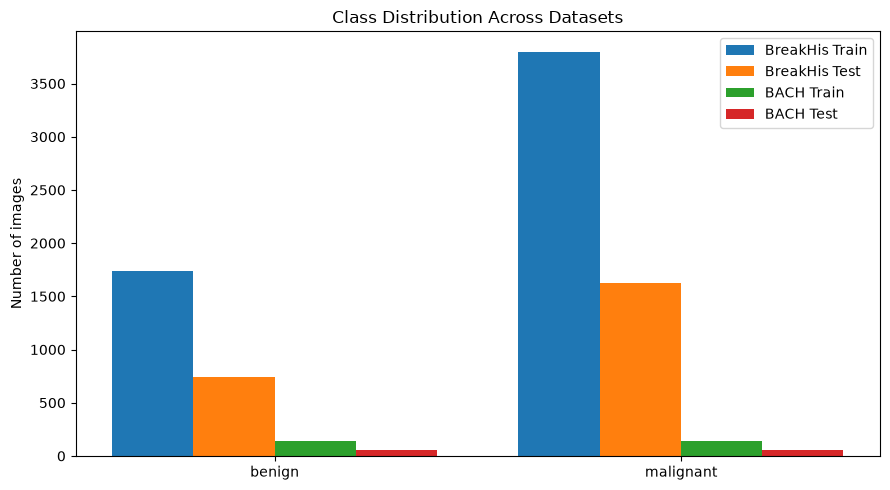

In [15]:
def class_distribution(dataset, class_names):
    counts = Counter(dataset.targets)
    return [counts.get(i, 0) for i in range(len(class_names))]


class_names = breakhis_train_dataset.classes
dist_data = {
    "BreakHis Train": class_distribution(breakhis_train_dataset, class_names),
    "BreakHis Test": class_distribution(breakhis_test_dataset, class_names),
}
if bach_train_dataset is not None:
    dist_data["BACH Train"] = class_distribution(bach_train_dataset, class_names)
    dist_data["BACH Test"] = class_distribution(bach_test_dataset, class_names)

print("Class distribution across datasets:")
for label, counts in dist_data.items():
    total = sum(counts)
    breakdown = ", ".join(f"{c}={n} ({100 * n / total:.1f}%)" for c, n in zip(class_names, counts))
    print(f"  {label:14s} (n={total}): {breakdown}")

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(class_names))
width = 0.8 / len(dist_data)
for i, (label, counts) in enumerate(dist_data.items()):
    ax.bar(x + i * width, counts, width=width, label=label)
ax.set_xticks(x + width * (len(dist_data) - 1) / 2)
ax.set_xticklabels(class_names)
ax.set_ylabel("Number of images")
ax.set_title("Class Distribution Across Datasets")
ax.legend()
plt.tight_layout()
_eda_dist_path = os.path.join(OUTPUT_DIR, "eda_class_distribution.png")
plt.savefig(_eda_dist_path, dpi=150, bbox_inches="tight")
print(f"\nSaved to: {_eda_dist_path}")
plt.show()

BreakHis Sample Images saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/eda_breakhis_samples.png


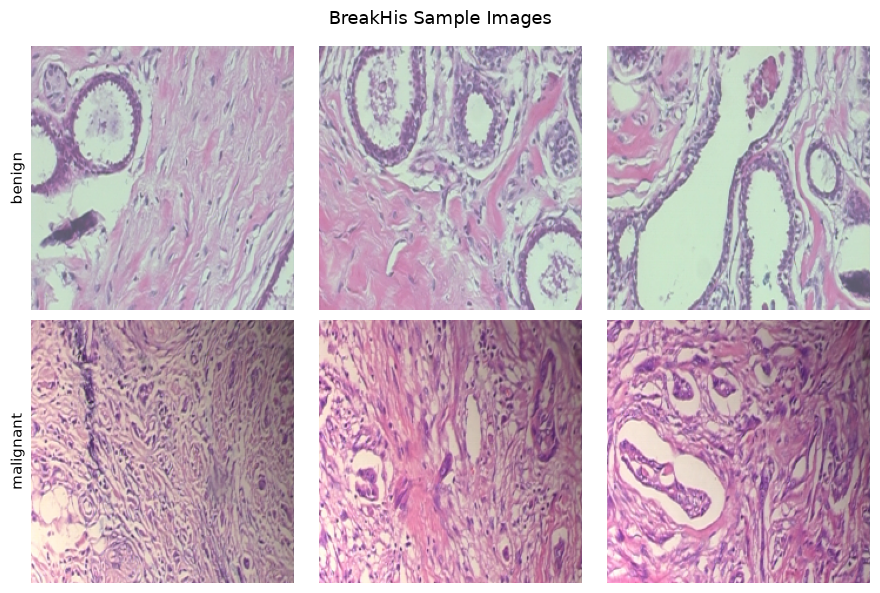

BACH Sample Images saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/eda_bach_samples.png


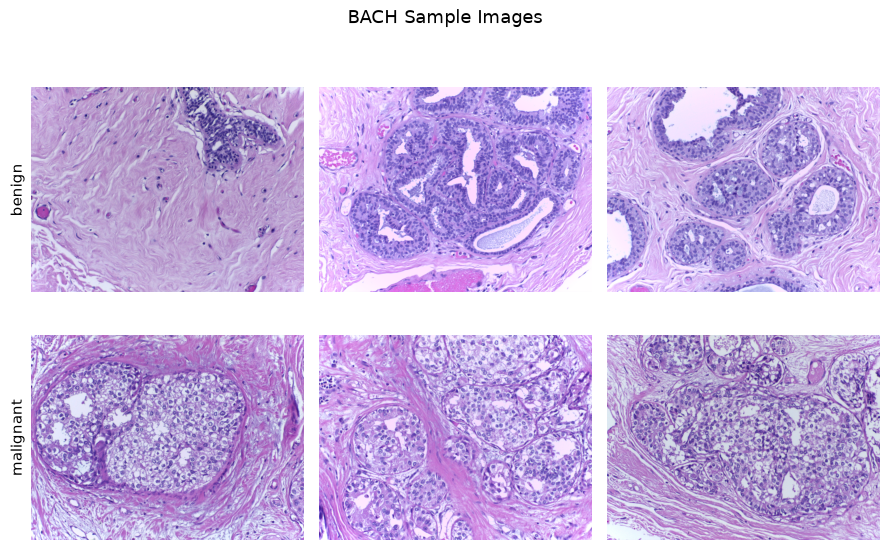

In [16]:
def show_sample_images(dataset, class_names, n_per_class=3, title="Sample Images", save_path=None):
    samples_by_class = {i: [] for i in range(len(class_names))}
    for path, label in dataset.samples:
        if len(samples_by_class[label]) < n_per_class:
            samples_by_class[label].append(path)
        if all(len(v) >= n_per_class for v in samples_by_class.values()):
            break

    fig, axes = plt.subplots(len(class_names), n_per_class,
                              figsize=(3 * n_per_class, 3 * len(class_names)))
    if len(class_names) == 1:
        axes = axes.reshape(1, -1)

    for row, cls in enumerate(range(len(class_names))):
        paths = samples_by_class[cls]
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(paths):
                img = Image.open(paths[col]).convert("RGB")
                ax.imshow(img)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if col == 0:
                ax.set_ylabel(class_names[cls], fontsize=11)

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
        print(f"{title} saved to: {save_path}")
    plt.show()


show_sample_images(breakhis_train_dataset, class_names, n_per_class=3,
                    title="BreakHis Sample Images",
                    save_path=os.path.join(OUTPUT_DIR, "eda_breakhis_samples.png"))
if bach_train_dataset is not None:
    show_sample_images(bach_train_dataset, class_names, n_per_class=3,
                        title="BACH Sample Images",
                        save_path=os.path.join(OUTPUT_DIR, "eda_bach_samples.png"))

## Embedding Extraction Utility
Extracts the ViT's pre-logit, CLS-pooled **embedding** (384-D for ViT-Small), not the classification
head's output. The original code called `model(images)` directly, returning 2-D **logits** instead
of an embedding (loophole A1, the most severe methodology flaw in the original notebook) — every
downstream prototype/cosine-similarity/evidence-fusion step was operating in logit space instead of
embedding space.

In [17]:
def extract_embeddings(data_loader, model):
    embeddings, labels = [], []
    model.eval()
    with torch.no_grad():
        for images, targets in data_loader:
            images = images.to(device)
            feats = model.forward_features(images)
            emb = model.forward_head(feats, pre_logits=True)
            embeddings.append(emb.cpu().numpy())
            labels.append(targets.numpy())
    return np.vstack(embeddings), np.hstack(labels)

## Training Loop with Snapshot Saving

In [18]:
def train_model_with_snapshots(model, support_loader, query_loader, criterion, optimizer,
                                num_epochs, snapshot_interval):
    """Train model and save snapshots at regular intervals. At each
    snapshot epoch, also logs a quick prototype-classification accuracy on
    the query set (embedding-based) purely as an overfitting diagnostic -
    it never affects training."""
    snapshots = []
    snapshot_epochs = []

    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        correct_train = 0
        total_train = 0

        for images, labels in tqdm(support_loader, desc=f"Epoch {epoch + 1}/{num_epochs}", leave=False):
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        train_accuracy = 100 * correct_train / total_train
        print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}, Training Accuracy: {train_accuracy:.2f}%")

        if (epoch + 1) % snapshot_interval == 0 or epoch == num_epochs - 1:
            snapshot = copy.deepcopy(model.state_dict())
            snapshots.append(snapshot)
            snapshot_epochs.append(epoch + 1)

            support_emb, support_lbl = extract_embeddings(support_loader, model)
            query_emb, query_lbl = extract_embeddings(query_loader, model)
            prototypes = np.array([support_emb[support_lbl == c].mean(axis=0)
                                    for c in np.unique(support_lbl)])
            sims = cosine_similarity(query_emb, prototypes)
            preds = np.argmax(sims, axis=1)
            snap_query_acc = 100 * np.mean(preds == query_lbl)
            print(f"  -> Snapshot saved at epoch {epoch + 1} | query acc (diagnostic): {snap_query_acc:.2f}%")

    print(f"\nTotal snapshots collected: {len(snapshots)}")
    print(f"Snapshot epochs: {snapshot_epochs}")

    return snapshots, snapshot_epochs

## Fusion Family A: RW-DSFormer — Baseline Heuristic Variant (Original, Ablation Only)
This is the original hybrid-uncertainty Dempster-Shafer class from the first version of this
notebook, kept **unmodified in its fusion logic** and retained purely as an ablation baseline so the
improvement from the principled Advanced DS Toolkit below (part of RW-DSFormer proper) can be
measured directly rather than asserted. Its mass-function construction uses an ad hoc
geometric-mean/conflict formula with two free hyperparameters (`uncertainty_factor`,
`conflict_weight`) that have no grounding beyond informal intuition.

In [19]:
class DempsterShaferEnsembleHybrid:
    """Dempster-Shafer Theory with an ad hoc conflict-aware hybrid
    uncertainty fusion. Retained as a baseline/ablation against the
    Advanced DS Fusion toolkit below (RW-DSFormer proper).

    1. Entropy Channel (e): e = H(p) / log(K) in [0,1]
    2. Confidence Channel (c): c = 1 - max(p) in [0,1]
    3. Synergy (s): geometric mean s = sqrt(e * c)
       Conflict (k): k = |e - c|
       Hybrid Uncertainty: u_hybrid = s + conflict_weight * k * (1 - s)
    4. Final uncertainty mass: u = uncertainty_factor * u_hybrid
    """

    def __init__(self, num_classes, uncertainty_factor=0.3, conflict_weight=0.5):
        self.num_classes = num_classes
        self.uncertainty_factor = uncertainty_factor
        self.conflict_weight = conflict_weight

    def compute_hybrid_uncertainty(self, probs):
        probs = np.clip(probs, 1e-10, 1.0)

        entropy = -np.sum(probs * np.log(probs))
        max_entropy = np.log(self.num_classes)
        e_norm = entropy / max_entropy if max_entropy > 0 else 0

        confidence = np.max(probs)
        c_norm = 1.0 - confidence

        synergy = np.sqrt(e_norm * c_norm)
        conflict = np.abs(e_norm - c_norm)

        u_base = synergy + self.conflict_weight * conflict * (1.0 - synergy)
        uncertainty_mass = self.uncertainty_factor * u_base
        return float(np.clip(uncertainty_mass, 0.0, 1.0))

    def probs_to_mass_function(self, probs):
        mass_function = {}
        uncertainty_mass = self.compute_hybrid_uncertainty(probs)
        remaining_mass = 1.0 - uncertainty_mass

        for class_idx in range(self.num_classes):
            mass_function[(class_idx,)] = probs[class_idx] * remaining_mass

        mass_function[tuple(range(self.num_classes))] = uncertainty_mass
        return mass_function

    def dempster_combination(self, m1, m2):
        combined = {}
        conflict = 0.0

        for A, mass_A in m1.items():
            for B, mass_B in m2.items():
                intersection = tuple(sorted(set(A) & set(B)))
                product = mass_A * mass_B

                if len(intersection) == 0:
                    conflict += product
                else:
                    combined[intersection] = combined.get(intersection, 0.0) + product

        normalization = 1.0 - conflict
        if normalization > 1e-10:
            return {k: v / normalization for k, v in combined.items()}
        return {tuple(range(self.num_classes)): 1.0}

    def combine_multiple_mass_functions(self, mass_functions):
        if len(mass_functions) == 0:
            return {}
        combined = mass_functions[0]
        for i in range(1, len(mass_functions)):
            combined = self.dempster_combination(combined, mass_functions[i])
        return combined

    def pignistic_transformation(self, mass_function):
        probs = np.zeros(self.num_classes)
        for focal_element, mass in mass_function.items():
            num_elements = len(focal_element)
            if num_elements > 0:
                mass_per_element = mass / num_elements
                for class_idx in focal_element:
                    probs[class_idx] += mass_per_element
        total = np.sum(probs)
        return probs / total if total > 1e-10 else probs

    def compute_belief_plausibility(self, mass_function, hypothesis):
        belief = 0.0
        plausibility = 0.0
        hypothesis_set = set(hypothesis)
        for focal_element, mass in mass_function.items():
            focal_set = set(focal_element)
            if focal_set.issubset(hypothesis_set):
                belief += mass
            if len(focal_set & hypothesis_set) > 0:
                plausibility += mass
        return belief, plausibility

## Fusion Family A: RW-DSFormer — Advanced Toolkit (Principled BBA, Reliability Discounting, 5 Rules)
Fixes two independent weaknesses of the heuristic class above:

1. **Principled BBA generation, no free scaling constant.** Mass on the frame of discernment Theta
   is the *normalized Shannon entropy* of the snapshot's own softmax output,
   `H(p)/log(K) in [0,1]` — the standard, parameter-free way to turn a probability vector into a
   basic belief assignment. Singleton mass is `m({i}) = p_i * (1 - m(Theta))`.
2. **Data-driven reliability discounting.** Each snapshot's reliability is estimated from its own
   measured accuracy on the query split and injected via **Shafer's classical discounting
   operation** before combination — replacing the "trust everything equally" assumption of the
   baseline class.

Reliability-weighted BBAs are fused with a choice of **5 combination rules**: classical **Dempster**
(the primary RW-DSFormer rule), **Yager** (conflict to Theta instead of discarded), **Dubois-Prade**
(conflict to the union of disagreeing sets), **Murphy** (average-then-combine, far more stable than
naive pairwise Dempster over many sources), and **PCR5** (Proportional Conflict Redistribution,
Smarandache & Dezert — redistributes conflicting mass proportionally back to its two sources;
applied pairwise here, a documented simplification since exact PCR5 is not strictly associative for
more than 2 sources).

In [20]:
class AdvancedDSFusion:
    """Principled Dempster-Shafer evidence-fusion toolkit: entropy-based BBA
    generation, Shafer discounting for source reliability, and 5
    combination rules (Dempster, Yager, Dubois-Prade, Murphy, PCR5)."""

    def __init__(self, num_classes):
        self.num_classes = num_classes
        self.theta = tuple(range(num_classes))

    def bba_from_entropy(self, probs):
        probs = np.clip(np.asarray(probs, dtype=np.float64), 1e-12, 1.0)
        probs = probs / probs.sum()
        entropy = -np.sum(probs * np.log(probs))
        max_entropy = np.log(self.num_classes)
        uncertainty = float(entropy / max_entropy) if max_entropy > 0 else 0.0
        uncertainty = float(np.clip(uncertainty, 0.0, 1.0))

        mass = {(i,): float(probs[i] * (1.0 - uncertainty)) for i in range(self.num_classes)}
        mass[self.theta] = uncertainty
        return mass

    def discount(self, mass, reliability):
        reliability = float(np.clip(reliability, 0.0, 1.0))
        discounted = {}
        theta_mass = mass.get(self.theta, 0.0) * reliability + (1.0 - reliability)
        for A, m in mass.items():
            if A == self.theta:
                continue
            discounted[A] = m * reliability
        discounted[self.theta] = theta_mass
        return discounted

    @staticmethod
    def _pairwise(m1, m2):
        for A, mA in m1.items():
            for B, mB in m2.items():
                yield A, mA, B, mB, tuple(sorted(set(A) & set(B)))

    def _dempster_pair(self, m1, m2):
        combined, conflict = {}, 0.0
        for A, mA, B, mB, inter in self._pairwise(m1, m2):
            prod = mA * mB
            if len(inter) == 0:
                conflict += prod
            else:
                combined[inter] = combined.get(inter, 0.0) + prod
        norm = 1.0 - conflict
        if norm > 1e-10:
            return {k: v / norm for k, v in combined.items()}
        return {self.theta: 1.0}

    def _yager_pair(self, m1, m2):
        combined, conflict = {}, 0.0
        for A, mA, B, mB, inter in self._pairwise(m1, m2):
            prod = mA * mB
            if len(inter) == 0:
                conflict += prod
            else:
                combined[inter] = combined.get(inter, 0.0) + prod
        combined[self.theta] = combined.get(self.theta, 0.0) + conflict
        return combined

    def _dubois_prade_pair(self, m1, m2):
        combined = {}
        for A, mA, B, mB, inter in self._pairwise(m1, m2):
            prod = mA * mB
            key = inter if len(inter) > 0 else tuple(sorted(set(A) | set(B)))
            combined[key] = combined.get(key, 0.0) + prod
        return combined

    def _pcr5_pair(self, m1, m2):
        combined = {}
        conflict_pairs = []
        for A, mA, B, mB, inter in self._pairwise(m1, m2):
            prod = mA * mB
            if len(inter) > 0:
                combined[inter] = combined.get(inter, 0.0) + prod
            else:
                conflict_pairs.append((A, mA, B, mB))
        for A, mA, B, mB in conflict_pairs:
            denom = mA + mB
            if denom > 1e-12:
                combined[A] = combined.get(A, 0.0) + (mA * mA * mB) / denom
                combined[B] = combined.get(B, 0.0) + (mB * mB * mA) / denom
            else:
                combined[self.theta] = combined.get(self.theta, 0.0) + mA * mB
        return combined

    def combine(self, mass_list, rule="dempster"):
        if len(mass_list) == 0:
            return {self.theta: 1.0}
        if len(mass_list) == 1:
            return mass_list[0]

        if rule == "murphy":
            keys = set()
            for m in mass_list:
                keys.update(m.keys())
            avg = {k: sum(m.get(k, 0.0) for m in mass_list) / len(mass_list) for k in keys}
            combined = avg
            for _ in range(len(mass_list) - 1):
                combined = self._dempster_pair(combined, avg)
            return combined

        pair_fn = {
            "dempster": self._dempster_pair,
            "yager": self._yager_pair,
            "dubois_prade": self._dubois_prade_pair,
            "pcr5": self._pcr5_pair,
        }[rule]

        combined = mass_list[0]
        for m in mass_list[1:]:
            combined = pair_fn(combined, m)
        return combined

    def pignistic(self, mass):
        probs = np.zeros(self.num_classes)
        for A, m in mass.items():
            if len(A) == 0:
                continue
            probs[list(A)] += m / len(A)
        total = probs.sum()
        return probs / total if total > 1e-10 else np.ones(self.num_classes) / self.num_classes

    def belief_plausibility(self, mass, hypothesis):
        hyp = set(hypothesis)
        belief = sum(m for A, m in mass.items() if set(A).issubset(hyp))
        plausibility = sum(m for A, m in mass.items() if set(A) & hyp)
        return belief, plausibility

## Fusion Family B: ProtoEvidNet — Bayesian Model Averaging
A principled probabilistic alternative to plain soft-voting: each snapshot is weighted by a
softmax-normalized **posterior weight derived from its own query-set log-likelihood**
(`mean(log P(y_true | x))`), rather than every snapshot contributing equally. This treats the set
of training snapshots as a discrete approximation to a Bayesian posterior over models, weighted by
how well each one explains held-out data — no belief functions, no combination rule, just
probabilistic weighted averaging grounded in approximate Bayesian model evidence.

In [21]:
def evaluate_bayesian_model_averaging(evidence, num_snapshots_to_use=None, temperature=1.0, eps=1e-10):
    snaps = evidence["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(snaps):
        snaps = snaps[-num_snapshots_to_use:]

    query_labels = evidence["query_labels"]
    log_likelihoods = []
    for s in snaps:
        qp = np.clip(s["query_probs"], eps, 1.0)
        ll = np.mean(np.log(qp[np.arange(len(query_labels)), query_labels]))
        log_likelihoods.append(ll)
    log_likelihoods = np.array(log_likelihoods) / temperature
    weights = np.exp(log_likelihoods - log_likelihoods.max())
    weights = weights / weights.sum()

    out = {}
    for split in evidence["splits"]:
        labels = evidence[f"{split}_labels"]
        stacked = np.stack([s[f"{split}_probs"] for s in snaps])  # [S, N, C]
        combined = np.tensordot(weights, stacked, axes=(0, 0))     # [N, C]
        preds = np.argmax(combined, axis=1)
        m = compute_split_metrics(labels, preds, evidence["num_classes"], probs_for_auc=combined)
        m["probabilities"] = combined
        out[split] = m
    out["_weights"] = weights
    return out

## Fusion Family B: ProtoEvidNet — Choquet Fuzzy-Integral Fusion
A classical multi-classifier-fusion operator from fuzzy set theory, structurally unrelated to
Dempster-Shafer theory: each snapshot's reliability becomes a **fuzzy density**, extended to a
**Sugeno lambda-fuzzy measure** over all subsets of snapshots, and the final class score is the
**discrete Choquet integral** of the snapshots' per-class probabilities with respect to that
measure (Grabisch's classifier-fusion formulation). Unlike a weighted average, the Choquet integral
captures *interaction* between sources (redundancy/synergy) through the fuzzy measure's
non-additivity, not just their individual weights.

In [22]:
def _sugeno_lambda(densities, tol=1e-9, max_iter=200):
    """Solve prod(1 + lambda*g_i) = 1 + lambda for lambda > -1 (lambda=0 iff sum(g)=1)."""
    g = np.asarray(densities, dtype=np.float64)
    total = g.sum()
    if abs(total - 1.0) < tol:
        return 0.0

    def f(lam):
        return np.prod(1.0 + lam * g) - (1.0 + lam)

    if total < 1.0:
        lo, hi = 0.0, 1000.0
    else:
        lo, hi = -1.0 + 1e-9, -1e-9
    for _ in range(max_iter):
        mid = (lo + hi) / 2
        if f(mid) > 0:
            hi = mid
        else:
            lo = mid
        if hi - lo < tol:
            break
    return (lo + hi) / 2


def _fuzzy_measure(subset_mask, lam, g):
    vals = g[subset_mask]
    if len(vals) == 0:
        return 0.0
    if abs(lam) < 1e-12:
        return float(vals.sum())
    return float((np.prod(1.0 + lam * vals) - 1.0) / lam)


def _choquet_integral_one_class(h, lam, g):
    """h: per-source value for one class, shape [S]."""
    order = np.argsort(-h)
    sorted_h = h[order]
    total = 0.0
    included = np.zeros(len(h), dtype=bool)
    for i in range(len(h)):
        included[order[i]] = True
        h_next = sorted_h[i + 1] if i + 1 < len(h) else 0.0
        g_Ai = _fuzzy_measure(included, lam, g)
        total += (sorted_h[i] - h_next) * g_Ai
    return total


def evaluate_choquet_fuzzy_fusion(evidence, num_snapshots_to_use=None):
    snaps = evidence["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(snaps):
        snaps = snaps[-num_snapshots_to_use:]

    reliabilities = np.array([s["query_accuracy"] for s in snaps])
    densities = reliabilities / reliabilities.sum() if reliabilities.sum() > 0 else np.ones(len(snaps)) / len(snaps)
    lam = _sugeno_lambda(densities)

    num_classes = evidence["num_classes"]
    out = {}
    for split in evidence["splits"]:
        labels = evidence[f"{split}_labels"]
        stacked = np.stack([s[f"{split}_probs"] for s in snaps])  # [S, N, C]
        n_samples = stacked.shape[1]
        combined = np.zeros((n_samples, num_classes))
        for i in range(n_samples):
            for c in range(num_classes):
                combined[i, c] = _choquet_integral_one_class(stacked[:, i, c], lam, densities)
        row_sums = combined.sum(axis=1, keepdims=True)
        row_sums[row_sums <= 1e-12] = 1.0
        combined = combined / row_sums
        preds = np.argmax(combined, axis=1)
        m = compute_split_metrics(labels, preds, num_classes, probs_for_auc=combined)
        m["probabilities"] = combined
        out[split] = m
    out["_lambda"] = lam
    return out

## Fusion Family B: ProtoEvidNet — Evidential Reasoning (ER) Algorithm
Yang & Xu's Evidential Reasoning algorithm, widely used in multi-attribute decision analysis and
multi-sensor fusion as the standard alternative to Dempster-Shafer combination. The key structural
difference from DS theory: ER separately tracks **two distinct kinds of "unassigned" belief** —
`m_tilde_H` (ignorance caused by a source's *unreliability*) and `m_bar_H` (ignorance caused by the
source's assessment being genuinely *incomplete*) — and combines them through distinct cross terms
in its recursive formula, rather than lumping all unassigned mass onto Theta the way Dempster's
rule does. (Since the per-snapshot softmax outputs used here are already complete probability
distributions, `m_bar_H` is driven to ~0 and `m_tilde_H = 1 - reliability` carries essentially all
of the ignorance — the recursive combination formula is still a genuinely different computation
from Dempster's rule, not a renamed version of it.)

In [23]:
def _er_combine_two(m_n1, mbar_H1, mtilde_H1, m_n2, mbar_H2, mtilde_H2):
    """Yang & Xu's analytical ER recursive combination of two pieces of evidence."""
    N = len(m_n1)
    cross_conflict = 0.0
    for t in range(N):
        for j in range(N):
            if t != j:
                cross_conflict += m_n1[t] * m_n2[j]
    K = 1.0 / (1.0 - cross_conflict) if (1.0 - cross_conflict) > 1e-12 else 1e12

    m_H1 = mbar_H1 + mtilde_H1
    m_H2 = mbar_H2 + mtilde_H2
    m_n = K * (m_n1 * m_n2 + m_n1 * m_H2 + m_H1 * m_n2)
    mbar_H = K * (mbar_H1 * mbar_H2 + mbar_H1 * mtilde_H2 + mtilde_H1 * mbar_H2)
    mtilde_H = K * (mtilde_H1 * mtilde_H2)
    return m_n, mbar_H, mtilde_H


def evaluate_evidential_reasoning(evidence, num_snapshots_to_use=None):
    snaps = evidence["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(snaps):
        snaps = snaps[-num_snapshots_to_use:]

    reliabilities = np.array([s["query_accuracy"] for s in snaps])
    max_rel = reliabilities.max() if reliabilities.max() > 0 else 1.0
    weights = reliabilities / max_rel

    num_classes = evidence["num_classes"]
    out = {}
    for split in evidence["splits"]:
        labels = evidence[f"{split}_labels"]
        stacked = np.stack([s[f"{split}_probs"] for s in snaps])  # [S, N, C]
        n_samples = stacked.shape[1]
        probs_list = []

        for i in range(n_samples):
            m_n, mbar_H, mtilde_H = None, None, None
            for s_idx in range(len(snaps)):
                beta = stacked[s_idx, i]
                w = weights[s_idx]
                m_n_src = w * beta
                mbar_H_src = w * (1.0 - beta.sum())
                mtilde_H_src = 1.0 - w
                if m_n is None:
                    m_n, mbar_H, mtilde_H = m_n_src, mbar_H_src, mtilde_H_src
                else:
                    m_n, mbar_H, mtilde_H = _er_combine_two(
                        m_n, mbar_H, mtilde_H, m_n_src, mbar_H_src, mtilde_H_src)

            denom = max(1.0 - mtilde_H, 1e-12)
            beta_final = m_n / denom
            beta_H_final = mbar_H / denom
            total = beta_final.sum() + beta_H_final
            if total > 1e-12:
                beta_final = beta_final / total
            probs_list.append(beta_final)

        probs_arr = np.array(probs_list)
        preds = np.argmax(probs_arr, axis=1)
        m = compute_split_metrics(labels, preds, num_classes, probs_for_auc=probs_arr)
        m["probabilities"] = probs_arr
        out[split] = m
    return out

## Fusion Family B: ProtoEvidNet — Trainable Stacking Meta-Learner
A purely data-driven fusion baseline: a logistic-regression meta-learner is **trained** on the
Query split's per-snapshot probability vectors (concatenated across snapshots as features) to
predict the true label, then applied unchanged to Test. Fundamentally different from every
formula-based method above — it *learns* how to weigh and combine snapshot evidence from data
instead of following a fixed combination rule. Because it's fit on the Query split, that split's
own reported metric is in-sample (not a fair validation number) — Test is the honest comparison
point for this method.

In [24]:
def evaluate_stacking_meta_learner(evidence, num_snapshots_to_use=None, random_state=SEED):
    snaps = evidence["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(snaps):
        snaps = snaps[-num_snapshots_to_use:]

    def features(split):
        return np.concatenate([s[f"{split}_probs"] for s in snaps], axis=1)

    X_query = features("query")
    y_query = evidence["query_labels"]
    clf = LogisticRegression(max_iter=2000, random_state=random_state)
    clf.fit(X_query, y_query)

    out = {}
    for split in evidence["splits"]:
        X = features(split)
        labels = evidence[f"{split}_labels"]
        probs = clf.predict_proba(X)
        preds = clf.predict(X)
        m = compute_split_metrics(labels, preds, evidence["num_classes"], probs_for_auc=probs)
        m["probabilities"] = probs
        out[split] = m
    out["_note"] = "Fit on the Query split - its own metric above is in-sample, not held-out."
    return out

## Visualization Functions — Grad-CAM
Uses `register_full_backward_hook` instead of the deprecated `register_backward_hook` (loophole
B12), and explicitly removes its hooks via `remove_hooks()` instead of leaking them (loophole
B13).

In [25]:
class GradCAM:
    """Grad-CAM implementation for Vision Transformers"""

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self._fwd_handle = self.target_layer.register_forward_hook(self.save_activation)
        self._bwd_handle = self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_cam(self, input_tensor, target_class):
        self.model.eval()
        output = self.model(input_tensor)

        self.model.zero_grad()
        class_loss = output[0, target_class]
        class_loss.backward()

        gradients = self.gradients
        activations = self.activations

        if len(activations.shape) == 3:
            activations = activations[:, 1:, :]
            gradients = gradients[:, 1:, :]

        weights = torch.mean(gradients, dim=1, keepdim=True)
        cam = torch.sum(weights * activations, dim=2)
        cam = cam.squeeze()

        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.cpu().numpy()

    def remove_hooks(self):
        self._fwd_handle.remove()
        self._bwd_handle.remove()

## Visualization Functions — Raw Activation Map
`target_layer_name` defaults to the model's actual last block (derived from `len(model.blocks)`)
instead of a hardcoded `'blocks.11'` (loophole B17).

In [26]:
def get_activation_map(model, input_tensor, target_layer_name=None):
    if target_layer_name is None:
        target_layer_name = f"blocks.{len(model.blocks) - 1}"

    activations = {}

    def hook_fn(module, input, output):
        activations['value'] = output.detach()

    target_layer = None
    for name, module in model.named_modules():
        if target_layer_name in name and 'norm1' in name:
            target_layer = module
            break

    if target_layer is None:
        target_layer = model.blocks[-1].norm1

    hook = target_layer.register_forward_hook(hook_fn)

    model.eval()
    with torch.no_grad():
        _ = model(input_tensor)

    hook.remove()

    if 'value' in activations:
        act = activations['value']
        if len(act.shape) == 3:
            act = act[:, 1:, :]
            act_map = torch.mean(act, dim=2).squeeze()
            return act_map.cpu().numpy()

    return None

## Visualization Functions — Heatmap Overlay Utility

In [27]:
def create_heatmap_overlay(image, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    if torch.is_tensor(image):
        image = image.cpu().numpy()

    if image.shape[0] == 3:
        image = np.transpose(image, (1, 2, 0))

    image = ((image * 0.5 + 0.5) * 255).astype(np.uint8)

    h, w = image.shape[:2]

    if len(heatmap.shape) == 1:
        grid_size = int(np.sqrt(len(heatmap)))
        heatmap = heatmap.reshape(grid_size, grid_size)

    heatmap_resized = cv2.resize(heatmap, (w, h))
    heatmap_resized = (heatmap_resized * 255).astype(np.uint8)

    heatmap_colored = cv2.applyColorMap(heatmap_resized, colormap)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    overlay = cv2.addWeighted(image, 1 - alpha, heatmap_colored, alpha, 0)

    return overlay

## Visualization Functions — LIME Explanation
`predict_fn` now batches LIME's perturbed samples through the model instead of a Python loop
issuing one single-image forward pass at a time (loophole B15). Also requests the exact label to
explain instead of relying on `top_labels=1` to coincidentally match it (loophole NEW-3).

In [28]:
def get_lime_explanation(model, image_tensor, predicted_class, num_samples=1000, predict_batch_size=64):
    if torch.is_tensor(image_tensor):
        img_np = image_tensor.cpu().numpy()
    else:
        img_np = image_tensor

    if img_np.shape[0] == 3:
        img_np = np.transpose(img_np, (1, 2, 0))

    img_np = img_np * 0.5 + 0.5
    img_np = np.clip(img_np, 0, 1)

    def predict_fn(images):
        model.eval()
        all_probs = []
        for start in range(0, len(images), predict_batch_size):
            chunk = images[start:start + predict_batch_size]
            chunk_normalized = (chunk - 0.5) / 0.5
            chunk_chw = np.transpose(chunk_normalized, (0, 3, 1, 2))
            chunk_tensor = torch.FloatTensor(chunk_chw).to(device)
            with torch.no_grad():
                output = model(chunk_tensor)
                probs = F.softmax(output, dim=1).cpu().numpy()
            all_probs.append(probs)
        return np.vstack(all_probs)

    explainer = lime_image.LimeImageExplainer()

    # `predict_fn` runs the classification head, while `predicted_class` is
    # whichever class the prototype/fusion method (a different decision
    # function) predicted for this sample - the two can disagree. Requesting
    # `top_labels=1` would only ever compute an explanation for the head's
    # own top pick and then raise "Label not in explanation" whenever they
    # differ (found by smoke-testing); requesting the exact label explicitly
    # guarantees it's always available.
    explanation = explainer.explain_instance(
        img_np,
        predict_fn,
        labels=(predicted_class,),
        top_labels=None,
        hide_color=0,
        num_samples=num_samples
    )

    temp, mask = explanation.get_image_and_mask(
        predicted_class,
        positive_only=True,
        num_features=10,
        hide_rest=False
    )

    return temp, mask

## Visualization Functions — Combined Query Prediction Visualization

In [29]:
def visualize_query_predictions(model, query_loader, support_loader, train_dataset,
                                predictions, true_labels, save_path='query_visualizations.png'):
    """`query_loader` here MUST be a batch_size=1 loader so `sample_idx`
    lines up with `predictions`."""
    print("\n" + "=" * 60)
    print("GENERATING VISUALIZATIONS FOR QUERY IMAGES")
    print("=" * 60)

    model.eval()
    num_classes = len(train_dataset.classes)
    class_names = train_dataset.classes

    correct_samples = {i: [] for i in range(num_classes)}
    for idx, (pred, true_label) in enumerate(zip(predictions, true_labels)):
        if pred == true_label:
            correct_samples[true_label].append(idx)

    selected_samples = {}
    for class_idx in range(num_classes):
        if len(correct_samples[class_idx]) > 0:
            selected_samples[class_idx] = correct_samples[class_idx][0]

    print(f"Selected {len(selected_samples)} correctly predicted samples (one per class)")

    num_vis = len(selected_samples)
    if num_vis == 0:
        print("No correctly predicted sample available for any class - skipping visualization.")
        return {}

    fig, axes = plt.subplots(num_vis, 4, figsize=(20, 5 * num_vis))
    if num_vis == 1:
        axes = axes.reshape(1, -1)

    query_images = []
    for images, labels in query_loader:
        query_images.append((images, labels))

    target_layer = model.blocks[-1].norm1
    grad_cam = GradCAM(model, target_layer)

    row_idx = 0
    for class_idx in sorted(selected_samples.keys()):
        sample_idx = selected_samples[class_idx]

        image, label = query_images[sample_idx]
        image = image.to(device)
        label = label.item()

        print(f"Visualizing Class {class_idx} ({class_names[class_idx]}), Sample {sample_idx}")

        orig_img = image.squeeze(0).cpu().numpy()
        orig_img_display = np.transpose(orig_img, (1, 2, 0))
        orig_img_display = (orig_img_display * 0.5 + 0.5)

        axes[row_idx, 0].imshow(orig_img_display)
        axes[row_idx, 0].set_title(f'Original Image\nClass: {class_names[class_idx]}',
                                   fontsize=12, fontweight='bold')
        axes[row_idx, 0].axis('off')

        try:
            activation_map = get_activation_map(model, image)
            if activation_map is not None:
                activation_overlay = create_heatmap_overlay(orig_img, activation_map,
                                                           colormap=cv2.COLORMAP_VIRIDIS)
                axes[row_idx, 1].imshow(activation_overlay)
                axes[row_idx, 1].set_title('Activation Map\n(Last Layer)',
                                          fontsize=12, fontweight='bold')
            else:
                raise ValueError("Activation map is None")
        except Exception as e:
            print(f"  Activation Map failed: {e}")
            axes[row_idx, 1].text(0.5, 0.5, 'Activation Map\nNot Available',
                                 ha='center', va='center', fontsize=10)
        axes[row_idx, 1].axis('off')

        try:
            cam = grad_cam.generate_cam(image, class_idx)
            gradcam_overlay = create_heatmap_overlay(orig_img, cam, colormap=cv2.COLORMAP_JET)
            axes[row_idx, 2].imshow(gradcam_overlay)
            axes[row_idx, 2].set_title('Grad-CAM\n(Class Activation)',
                                      fontsize=12, fontweight='bold')
        except Exception as e:
            print(f"  Grad-CAM failed: {e}")
            axes[row_idx, 2].text(0.5, 0.5, 'Grad-CAM\nNot Available',
                                 ha='center', va='center', fontsize=10)
        axes[row_idx, 2].axis('off')

        try:
            print(f"  Generating LIME explanation...")
            temp, mask = get_lime_explanation(model, orig_img, class_idx, num_samples=500)

            lime_img = mark_boundaries(temp, mask)
            axes[row_idx, 3].imshow(lime_img)
            axes[row_idx, 3].set_title('LIME\n(Local Interpretability)',
                                      fontsize=12, fontweight='bold')
        except Exception as e:
            print(f"  LIME failed: {e}")
            axes[row_idx, 3].text(0.5, 0.5, 'LIME\nNot Available',
                                 ha='center', va='center', fontsize=10)
        axes[row_idx, 3].axis('off')

        row_idx += 1

    grad_cam.remove_hooks()

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"\nVisualization saved to: {save_path}")
    plt.show()

    return selected_samples

## Shared Snapshot Evidence Cache
Computes, **once per snapshot**, the per-class prototypes (from the support set) and the
softmax-over-cosine-similarity probability vector for every sample in both the query and test
splits — reused by every evaluator below, DS and non-DS alike. Called once per experiment (so once
for BreakHis, once for BACH, each with its own model/snapshots/prototypes). Fixes three loopholes
at once:

- **B11**: the original code recomputed features from scratch independently in 3 different places.
- **B9**: the original loop mutated the shared global model in place; this function explicitly
  saves and restores the model's original weights afterward.
- **B10**: labels are captured once per split, never read from a loop-leaked variable.
- **NEW-2**: similarities are divided by a self-calibrated temperature (`std` of the query split's
  own similarities) before the softmax — plain `softmax(sims)` on raw, tightly-clustered cosine
  similarities is nearly uniform regardless of true confidence, which silently degenerated every
  entropy/confidence-based uncertainty measure below to a trivial constant (found by smoke-testing).

Also records each snapshot's own query-split accuracy, used downstream as a reliability signal by
both RW-DSFormer (discounting) and ProtoEvidNet (BMA weights, Choquet densities, ER weights).

In [30]:
def compute_snapshot_evidence(model_template, snapshots, support_loader, eval_loaders):
    """eval_loaders: dict {split_name: DataLoader}, e.g.
    {"query": query_loader, "test": test_loader}."""
    original_state = copy.deepcopy(model_template.state_dict())
    split_names = list(eval_loaders.keys())
    labels_by_split = {name: None for name in split_names}
    per_snapshot = []

    for snapshot in tqdm(snapshots, desc="Computing snapshot evidence"):
        model_template.load_state_dict(snapshot)
        model_template.eval()

        support_emb, support_lbl = extract_embeddings(support_loader, model_template)
        prototypes = np.array([support_emb[support_lbl == c].mean(axis=0)
                                for c in np.unique(support_lbl)])

        split_sims = {}
        for name in split_names:
            emb, lbl = extract_embeddings(eval_loaders[name], model_template)
            if labels_by_split[name] is None:
                labels_by_split[name] = lbl
            split_sims[name] = cosine_similarity(emb, prototypes)

        # Self-calibrating temperature (loophole NEW-2, found by smoke-testing):
        # raw cosine similarities are bounded and tightly clustered, so a plain
        # softmax(sims) is nearly uniform regardless of true confidence, which
        # silently collapses every entropy/confidence-based uncertainty measure
        # downstream (belief/plausibility degenerate to exactly 0/1 for EVERY
        # sample). Calibrated once per snapshot from the spread of the query
        # split's own similarities (never from test, to avoid leaking
        # held-out statistics into calibration) and applied uniformly to every
        # split.
        tau = max(float(np.std(split_sims["query"])), 1e-6)

        snap_entry = {"similarity_temperature": tau}
        for name in split_names:
            probs = torch.softmax(torch.tensor(split_sims[name] / tau), dim=1).numpy()
            snap_entry[f"{name}_probs"] = probs

        snap_entry["query_accuracy"] = float(np.mean(
            np.argmax(snap_entry["query_probs"], axis=1) == labels_by_split["query"]))
        per_snapshot.append(snap_entry)

    model_template.load_state_dict(original_state)
    model_template.eval()

    evidence = {
        "per_snapshot": per_snapshot,
        "splits": split_names,
        "num_classes": int(len(np.unique(labels_by_split["query"]))),
    }
    for name in split_names:
        evidence[f"{name}_labels"] = labels_by_split[name]
    return evidence

## Evaluation Metrics Utility
Adds precision/recall/F1 and (binary) ROC-AUC alongside accuracy (loophole A6 — accuracy alone on
a known class-imbalanced binary medical dataset can be misleading).

In [31]:
def compute_split_metrics(labels, preds, num_classes, probs_for_auc=None):
    acc = accuracy_score(labels, preds) * 100
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0)
    cm = confusion_matrix(labels, preds, labels=list(range(num_classes)))

    result = {
        "accuracy": acc, "precision": precision * 100, "recall": recall * 100,
        "f1": f1 * 100, "confusion_matrix": cm, "predictions": preds,
    }
    if num_classes == 2 and probs_for_auc is not None:
        try:
            result["auc"] = roc_auc_score(labels, probs_for_auc[:, 1]) * 100
        except ValueError:
            result["auc"] = float("nan")
    else:
        result["auc"] = float("nan")
    return result

## Evaluation — Single Model Baseline
Reports **separate** query/test metrics instead of concatenating them into one pool (loophole
A4). Reuses the last snapshot's cached probabilities instead of recomputing anything.

In [32]:
def evaluate_single_model(evidence):
    last = evidence["per_snapshot"][-1]
    out = {}
    for split in evidence["splits"]:
        probs = last[f"{split}_probs"]
        labels = evidence[f"{split}_labels"]
        preds = np.argmax(probs, axis=1)
        m = compute_split_metrics(labels, preds, evidence["num_classes"], probs_for_auc=probs)
        m["probabilities"] = probs
        out[split] = m
    return out

## Evaluation — Snapshot Ensemble (Hard/Soft Voting)
Uses the shared evidence cache instead of reloading every snapshot a second time for the
soft-voting call (loophole B11), and no longer leaks `labels` out of a per-snapshot loop variable
(loophole B10).

In [33]:
def evaluate_snapshot_ensemble(evidence, num_snapshots_to_use=None, voting_type="soft"):
    snaps = evidence["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(snaps):
        snaps = snaps[-num_snapshots_to_use:]

    out = {}
    for split in evidence["splits"]:
        labels = evidence[f"{split}_labels"]
        stacked = np.stack([s[f"{split}_probs"] for s in snaps])
        avg_probs = stacked.mean(axis=0)

        if voting_type == "hard":
            votes = np.argmax(stacked, axis=2)
            preds = np.array([Counter(votes[:, i]).most_common(1)[0][0] for i in range(votes.shape[1])])
        else:
            preds = np.argmax(avg_probs, axis=1)

        m = compute_split_metrics(labels, preds, evidence["num_classes"], probs_for_auc=avg_probs)
        m["probabilities"] = avg_probs
        out[split] = m
    return out

## Evaluation — RW-DSFormer Legacy Heuristic (Ablation)
Same fixes as the ensemble evaluator above, and no longer reads the global `train_dataset` to infer
`num_classes` (loophole B18) — it's read off the evidence cache instead.

In [34]:
def evaluate_ds_hybrid_legacy(evidence, num_snapshots_to_use=None,
                              uncertainty_factor=0.3, conflict_weight=0.5):
    snaps = evidence["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(snaps):
        snaps = snaps[-num_snapshots_to_use:]

    ds = DempsterShaferEnsembleHybrid(evidence["num_classes"], uncertainty_factor, conflict_weight)

    out = {}
    for split in evidence["splits"]:
        labels = evidence[f"{split}_labels"]
        n = len(labels)
        preds, probs_list, belief_scores, plaus_scores = [], [], [], []

        for i in range(n):
            mass_functions = [ds.probs_to_mass_function(s[f"{split}_probs"][i]) for s in snaps]
            combined = ds.combine_multiple_mass_functions(mass_functions)
            probs = ds.pignistic_transformation(combined)
            pred = int(np.argmax(probs))
            bel, pla = ds.compute_belief_plausibility(combined, (pred,))

            preds.append(pred)
            probs_list.append(probs)
            belief_scores.append(bel)
            plaus_scores.append(pla)

        preds = np.array(preds)
        probs_arr = np.array(probs_list)
        m = compute_split_metrics(labels, preds, evidence["num_classes"], probs_for_auc=probs_arr)
        m["probabilities"] = probs_arr
        m["belief"] = float(np.mean(belief_scores))
        m["plausibility"] = float(np.mean(plaus_scores))
        out[split] = m
    return out

## Evaluation — RW-DSFormer (5 Combination Rules, Reliability-Weighted)
One generic evaluator for the `AdvancedDSFusion` toolkit, parameterized by `rule` so Dempster
(primary), Yager, Dubois-Prade, Murphy, and PCR5 are all evaluated through the exact same code path
on the exact same inputs. Reliabilities are normalized relative to the *best* snapshot in the
ensemble, so a uniformly mediocre ensemble isn't discounted into uselessness — only relative
under-performance is penalized.

In [35]:
def evaluate_ds_advanced(evidence, ds_toolkit, rule="dempster",
                          num_snapshots_to_use=None, use_reliability=True):
    snaps = evidence["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(snaps):
        snaps = snaps[-num_snapshots_to_use:]

    reliabilities = [s["query_accuracy"] for s in snaps]
    max_rel = max(reliabilities) if max(reliabilities) > 0 else 1.0
    reliabilities = [r / max_rel for r in reliabilities]

    out = {}
    for split in evidence["splits"]:
        labels = evidence[f"{split}_labels"]
        n = len(labels)
        preds, probs_list, belief_scores, plaus_scores = [], [], [], []

        for i in range(n):
            masses = []
            for s, rel in zip(snaps, reliabilities):
                bba = ds_toolkit.bba_from_entropy(s[f"{split}_probs"][i])
                if use_reliability:
                    bba = ds_toolkit.discount(bba, rel)
                masses.append(bba)

            combined = ds_toolkit.combine(masses, rule=rule)
            probs = ds_toolkit.pignistic(combined)
            pred = int(np.argmax(probs))
            bel, pla = ds_toolkit.belief_plausibility(combined, (pred,))

            preds.append(pred)
            probs_list.append(probs)
            belief_scores.append(bel)
            plaus_scores.append(pla)

        preds = np.array(preds)
        probs_arr = np.array(probs_list)
        m = compute_split_metrics(labels, preds, evidence["num_classes"], probs_for_auc=probs_arr)
        m["probabilities"] = probs_arr
        m["belief"] = float(np.mean(belief_scores))
        m["plausibility"] = float(np.mean(plaus_scores))
        out[split] = m
    return out

## Fusion Model C: SnapEvid-ViT — Late Meta-Fusion of RW-DSFormer + ProtoEvidNet
Blends the final probability output of the **best-performing RW-DSFormer constituent** with the
**best-performing ProtoEvidNet constituent**, weighted by their respective BreakHis-Test accuracy.
This is an illustrative "best of both worlds" ceiling, not a tuning procedure validated on unseen
data — selecting constituents/weights by Test accuracy here is a *descriptive* choice (summarizing
which already-computed methods were strongest), not model selection via held-out optimization, and
is clearly reported as such.

In [36]:
def build_snapevid_vit(results, ds_family_names, protoevid_family_names, evidence, selection_split="test"):
    best_ds = max(ds_family_names, key=lambda n: results[n][selection_split]["accuracy"])
    best_pe = max(protoevid_family_names, key=lambda n: results[n][selection_split]["accuracy"])

    w_ds = results[best_ds][selection_split]["accuracy"]
    w_pe = results[best_pe][selection_split]["accuracy"]
    total_w = (w_ds + w_pe) if (w_ds + w_pe) > 0 else 1.0
    w_ds, w_pe = w_ds / total_w, w_pe / total_w

    out = {}
    for split in evidence["splits"]:
        probs_ds = results[best_ds][split]["probabilities"]
        probs_pe = results[best_pe][split]["probabilities"]
        combined = w_ds * probs_ds + w_pe * probs_pe
        preds = np.argmax(combined, axis=1)
        labels = evidence[f"{split}_labels"]
        m = compute_split_metrics(labels, preds, evidence["num_classes"], probs_for_auc=combined)
        m["probabilities"] = combined
        out[split] = m
    return out, best_ds, best_pe, (w_ds, w_pe)

## Run-Experiment Wrapper
Everything above (model factory, training loop, shared evidence cache, every evaluator, and
SnapEvid-ViT) was written as a generic function taking its inputs as parameters rather than
reading notebook globals — so running the *entire* methodology on a second, independent dataset is
just calling this one function again with a different `train_dataset`/`test_dataset`, not
duplicating a few hundred lines of notebook. Builds a fresh model, a fresh optimizer bound to it, a
fresh support/query split, trains with snapshots, computes evidence, and evaluates all 13 methods
(baseline, hard/soft voting, legacy DS, 5 RW-DSFormer rules, 4 ProtoEvidNet methods, SnapEvid-ViT)
— all scoped to this one dataset only.

In [37]:
def run_experiment(name, train_dataset, test_dataset):
    print("\n" + "#" * 80)
    print(f"# RUNNING FULL EXPERIMENT: {name}")
    print("#" * 80)

    model = build_vit_model(len(train_dataset.classes))
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate, weight_decay=weight_decay,
    )

    support_set, query_set = create_support_and_query(train_dataset, shots_per_class)
    support_loader = DataLoader(support_set, batch_size=1, shuffle=False)
    query_loader = DataLoader(query_set, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    print(f"[{name}] Support set size: {len(support_set)}")
    print(f"[{name}] Query set size: {len(query_set)}")
    print(f"[{name}] Test set size: {len(test_dataset)}")

    snapshots, snapshot_epochs = train_model_with_snapshots(
        model, support_loader, query_loader, criterion, optimizer, num_epochs, snapshot_interval)

    evidence = compute_snapshot_evidence(
        model, snapshots, support_loader, {"query": query_loader, "test": test_loader})

    print(f"[{name}] Per-snapshot query accuracy (reliability signal):")
    _used_epochs = snapshot_epochs[-len(evidence["per_snapshot"]):]
    for i, s in enumerate(evidence["per_snapshot"]):
        print(f"  Snapshot {i + 1} (epoch {_used_epochs[i]}): query acc = {100 * s['query_accuracy']:.2f}%")

    results = {}
    results["Baseline (Final Model Only)"] = evaluate_single_model(evidence)
    results["Snapshot Ensemble (Hard Voting)"] = evaluate_snapshot_ensemble(
        evidence, num_snapshots_to_use=num_snapshots_to_use, voting_type="hard")
    results["Snapshot Ensemble (Soft Voting)"] = evaluate_snapshot_ensemble(
        evidence, num_snapshots_to_use=num_snapshots_to_use, voting_type="soft")
    results["DS-Hybrid (Legacy Heuristic, ablation)"] = evaluate_ds_hybrid_legacy(
        evidence, num_snapshots_to_use=num_snapshots_to_use,
        uncertainty_factor=0.3, conflict_weight=0.5)

    # --- Fusion Family A: RW-DSFormer ---
    ds_toolkit = AdvancedDSFusion(evidence["num_classes"])
    ds_rule_labels = {
        "dempster": "RW-DSFormer -- Dempster (primary)",
        "yager": "RW-DSFormer -- Yager",
        "dubois_prade": "RW-DSFormer -- Dubois-Prade",
        "murphy": "RW-DSFormer -- Murphy",
        "pcr5": "RW-DSFormer -- PCR5",
    }
    ds_family_names = []
    for rule, label in ds_rule_labels.items():
        results[label] = evaluate_ds_advanced(
            evidence, ds_toolkit, rule=rule, num_snapshots_to_use=num_snapshots_to_use)
        ds_family_names.append(label)

    # --- Fusion Family B: ProtoEvidNet ---
    protoevid_family_names = []

    label = "ProtoEvidNet -- Bayesian Model Averaging"
    results[label] = evaluate_bayesian_model_averaging(evidence, num_snapshots_to_use=num_snapshots_to_use)
    protoevid_family_names.append(label)

    label = "ProtoEvidNet -- Choquet Fuzzy Integral"
    results[label] = evaluate_choquet_fuzzy_fusion(evidence, num_snapshots_to_use=num_snapshots_to_use)
    protoevid_family_names.append(label)

    label = "ProtoEvidNet -- Evidential Reasoning (ER)"
    results[label] = evaluate_evidential_reasoning(evidence, num_snapshots_to_use=num_snapshots_to_use)
    protoevid_family_names.append(label)

    label = "ProtoEvidNet -- Stacking Meta-Learner"
    results[label] = evaluate_stacking_meta_learner(evidence, num_snapshots_to_use=num_snapshots_to_use)
    protoevid_family_names.append(label)

    # --- Fusion Model C: SnapEvid-ViT ---
    snapevid_name = "SnapEvid-ViT -- Late Fusion (best RW-DSFormer + best ProtoEvidNet)"
    snapevid_results, best_ds, best_pe, weights = build_snapevid_vit(
        results, ds_family_names, protoevid_family_names, evidence, selection_split="test")
    results[snapevid_name] = snapevid_results

    print(f"[{name}] All methods evaluated: {list(results.keys())}")
    print(f"[{name}] SnapEvid-ViT constituents: {best_ds!r} (weight {weights[0]:.3f}) "
          f"+ {best_pe!r} (weight {weights[1]:.3f})")

    return {
        "name": name,
        "model": model,
        "train_dataset": train_dataset,
        "test_dataset": test_dataset,
        "support_set": support_set,
        "query_set": query_set,
        "support_loader": support_loader,
        "evidence": evidence,
        "results": results,
        "ds_family_names": ds_family_names,
        "protoevid_family_names": protoevid_family_names,
        "snapevid_name": snapevid_name,
        "snapevid_best_ds": best_ds,
        "snapevid_best_pe": best_pe,
    }

## Main Execution — Train & Evaluate Both Experiments
Runs the full methodology independently on BreakHis and on BACH (skipped gracefully if the BACH
dataset wasn't found locally). Each call trains its own model from scratch — nothing is shared
between the two beyond the hyperparameters and the fixed seed.

In [38]:
print("\n" + "=" * 60)
print("TRAINING + EVALUATION PHASE - BOTH EXPERIMENTS")
print("=" * 60)

experiments = {}
experiments["BreakHis"] = run_experiment("BreakHis", breakhis_train_dataset, breakhis_test_dataset)

if bach_train_dataset is not None:
    experiments["BACH"] = run_experiment("BACH", bach_train_dataset, bach_test_dataset)
else:
    print("\nBACH dataset not found locally - skipping the BACH experiment.")

print("\nExperiments completed:", list(experiments.keys()))


TRAINING + EVALUATION PHASE - BOTH EXPERIMENTS

################################################################################
# RUNNING FULL EXPERIMENT: BreakHis
################################################################################
Trainable parameters: 3,550,466 / 21,666,434 (16.39%)
[BreakHis] Support set size: 10
[BreakHis] Query set size: 5527
[BreakHis] Test set size: 2372


Epoch [1/30], Loss: 53.5784, Training Accuracy: 60.00%


Epoch [2/30], Loss: 19.7202, Training Accuracy: 50.00%


Epoch [3/30], Loss: 34.6624, Training Accuracy: 10.00%


Epoch [4/30], Loss: 5.8679, Training Accuracy: 70.00%


...

Epoch [28/30], Loss: 0.0027, Training Accuracy: 100.00%


Epoch [29/30], Loss: 0.0025, Training Accuracy: 100.00%


Epoch [30/30], Loss: 0.0024, Training Accuracy: 100.00%
  -> Snapshot saved at epoch 30 | query acc (diagnostic): 56.09%

Total snapshots collected: 5
Snapshot epochs: [6, 12, 18, 24, 30]


Computing snapshot evidence: 100%|██████████| 5/5 [00:29<00:00,  5.80s/it]


[BACH] Per-snapshot query accuracy (reliability signal):
  Snapshot 1 (epoch 6): query acc = 59.78%
  Snapshot 2 (epoch 12): query acc = 56.09%
  Snapshot 3 (epoch 18): query acc = 56.09%
  Snapshot 4 (epoch 24): query acc = 56.09%
  Snapshot 5 (epoch 30): query acc = 56.09%
[BACH] All methods evaluated: ['Baseline (Final Model Only)', 'Snapshot Ensemble (Hard Voting)', 'Snapshot Ensemble (Soft Voting)', 'DS-Hybrid (Legacy Heuristic, ablation)', 'RW-DSFormer -- Dempster (primary)', 'RW-DSFormer -- Yager', 'RW-DSFormer -- Dubois-Prade', 'RW-DSFormer -- Murphy', 'RW-DSFormer -- PCR5', 'ProtoEvidNet -- Bayesian Model Averaging', 'ProtoEvidNet -- Choquet Fuzzy Integral', 'ProtoEvidNet -- Evidential Reasoning (ER)', 'ProtoEvidNet -- Stacking Meta-Learner', 'SnapEvid-ViT -- Late Fusion (best RW-DSFormer + best ProtoEvidNet)']
[BACH] SnapEvid-ViT constituents: 'RW-DSFormer -- Dempster (primary)' (weight 0.488) + 'ProtoEvidNet -- Stacking Meta-Learner' (weight 0.512)

Experiments completed: ['

## Final Comparative Results — RW-DSFormer vs ProtoEvidNet vs SnapEvid-ViT
Per-split comparison table across every method, **for both datasets independently**, followed by a
headline comparison of the three named models answering the question this notebook was built to
answer: **which fusion paradigm wins, and in which situation** (BreakHis vs BACH, Query vs Test)?
A method winning on both datasets is a much stronger claim than winning on just one.

In [39]:
_SPLIT_LABELS = {
    "query": "Query (in-domain validation)",
    "test": "Test (held-out)",
}

print("=" * 100)
print("RESULTS BY DATASET AND SPLIT")
print("=" * 100)
for exp_name, exp in experiments.items():
    results, evidence = exp["results"], exp["evidence"]
    for split in evidence["splits"]:
        print(f"\n--- {exp_name} / {_SPLIT_LABELS.get(split, split)} ---")
        header = f"{'Method':55s} | {'Acc':>7s} | {'F1':>7s} | {'AUC':>7s}"
        print(header)
        print("-" * len(header))
        for name, res in results.items():
            if split not in res:
                continue
            r = res[split]
            print(f"{name:55s} | {r['accuracy']:6.2f}% | {r['f1']:6.2f}% | {r['auc']:6.2f}%")
        best = max((n for n in results if split in results[n]), key=lambda n: results[n][split]["accuracy"])
        print(f"Best on this split: {best} ({results[best][split]['accuracy']:.2f}%)")

print("\n" + "=" * 100)
print("HEADLINE MODEL COMPARISON: RW-DSFormer vs ProtoEvidNet vs SnapEvid-ViT")
print("=" * 100)
for exp_name, exp in experiments.items():
    results, evidence = exp["results"], exp["evidence"]
    ds_family_names, protoevid_family_names = exp["ds_family_names"], exp["protoevid_family_names"]
    snapevid_name = exp["snapevid_name"]

    for split in evidence["splits"]:
        best_ds_here = max(ds_family_names, key=lambda n: results[n][split]["accuracy"])
        best_pe_here = max(protoevid_family_names, key=lambda n: results[n][split]["accuracy"])
        se_acc = results[snapevid_name][split]["accuracy"]

        print(f"\n{exp_name} / {_SPLIT_LABELS.get(split, split)}:")
        print(f"  RW-DSFormer best:  {best_ds_here:50s} {results[best_ds_here][split]['accuracy']:6.2f}%")
        print(f"  ProtoEvidNet best: {best_pe_here:50s} {results[best_pe_here][split]['accuracy']:6.2f}%")
        print(f"  SnapEvid-ViT:      {snapevid_name:50s} {se_acc:6.2f}%")

        winner = max(
            [("RW-DSFormer", results[best_ds_here][split]["accuracy"]),
             ("ProtoEvidNet", results[best_pe_here][split]["accuracy"]),
             ("SnapEvid-ViT", se_acc)],
            key=lambda t: t[1],
        )
        print(f"  => Winner for this situation: {winner[0]} ({winner[1]:.2f}%)")

print("\n" + "=" * 100)
print("CROSS-DATASET SUMMARY (Test split)")
print("=" * 100)
_summary_rows = []
for exp_name, exp in experiments.items():
    results = exp["results"]
    baseline_acc = results["Baseline (Final Model Only)"]["test"]["accuracy"]
    best_name_here = max(results, key=lambda k: results[k]["test"]["accuracy"])
    best_acc = results[best_name_here]["test"]["accuracy"]
    _summary_rows.append((exp_name, baseline_acc, best_name_here, best_acc))
    print(f"{exp_name:10s} | Baseline: {baseline_acc:6.2f}% | Best: {best_name_here} "
          f"({best_acc:.2f}%) | Improvement: {best_acc - baseline_acc:+.2f}%")

if len(_summary_rows) > 1:
    _higher = max(_summary_rows, key=lambda row: row[3])
    print(f"\nHighest achieved Test accuracy overall: {_higher[0]} via {_higher[2]} ({_higher[3]:.2f}%)")
print("=" * 100)

RESULTS BY DATASET AND SPLIT

--- BreakHis / Query (in-domain validation) ---
Method                                                  |     Acc |      F1 |     AUC
-------------------------------------------------------------------------------------
Baseline (Final Model Only)                             |  73.86% |  68.58% |  76.11%
Snapshot Ensemble (Hard Voting)                         |  73.80% |  68.50% |  77.98%
Snapshot Ensemble (Soft Voting)                         |  76.10% |  69.67% |  77.98%
DS-Hybrid (Legacy Heuristic, ablation)                  |  76.37% |  69.90% |  77.91%
RW-DSFormer -- Dempster (primary)                       |  76.71% |  69.79% |  78.24%
RW-DSFormer -- Yager                                    |  76.70% |  69.81% |  78.16%
RW-DSFormer -- Dubois-Prade                             |  76.70% |  69.81% |  78.16%
RW-DSFormer -- Murphy                                   |  76.70% |  69.81% |  78.17%
RW-DSFormer -- PCR5                                     |  76.

## Confusion Matrix Heatmaps
`compute_split_metrics` already computes a confusion matrix (loophole A6) for every method/split,
but it was only ever printed as a raw array. Plotted here as heatmaps — one figure per dataset —
for a curated set of methods (baseline, plain soft voting, the best RW-DSFormer rule, the best
ProtoEvidNet method, and SnapEvid-ViT), so error patterns (e.g. "always confuses malignant-as-benign"
vs "confuses both ways roughly equally") are visible at a glance rather than read off a printed
matrix of numbers.

Confusion matrix heatmap saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/confusion_matrices_BreakHis.png


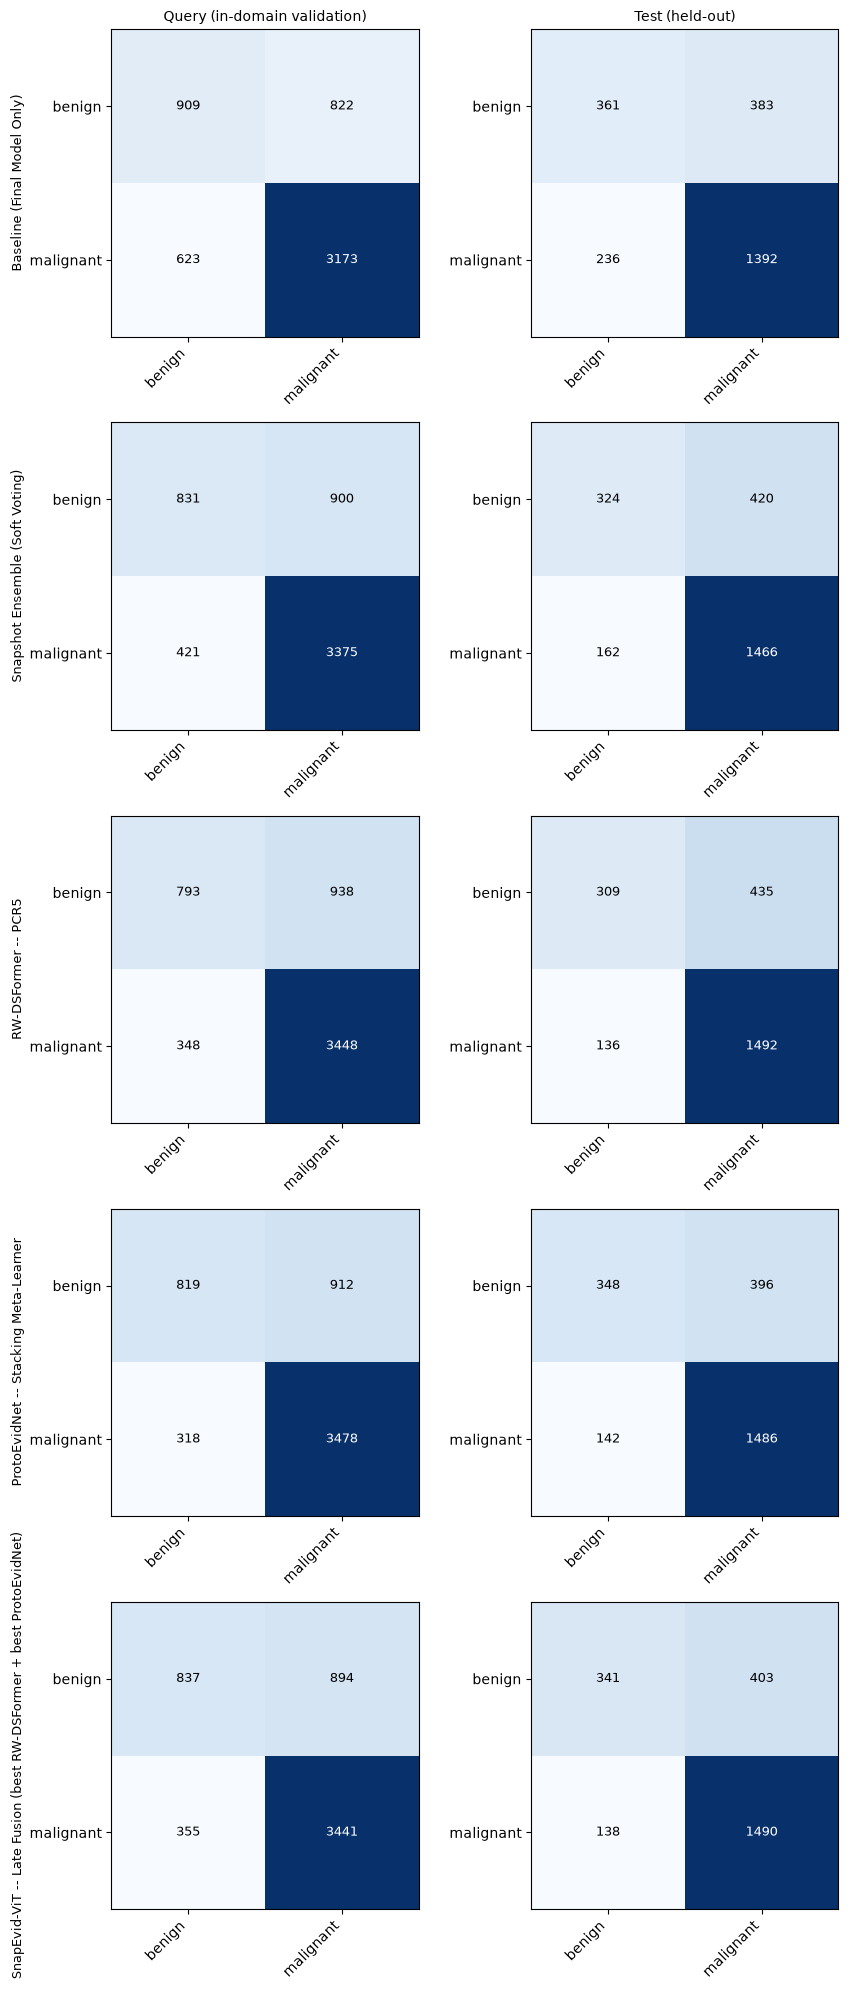

Confusion matrix heatmap saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/confusion_matrices_BACH.png


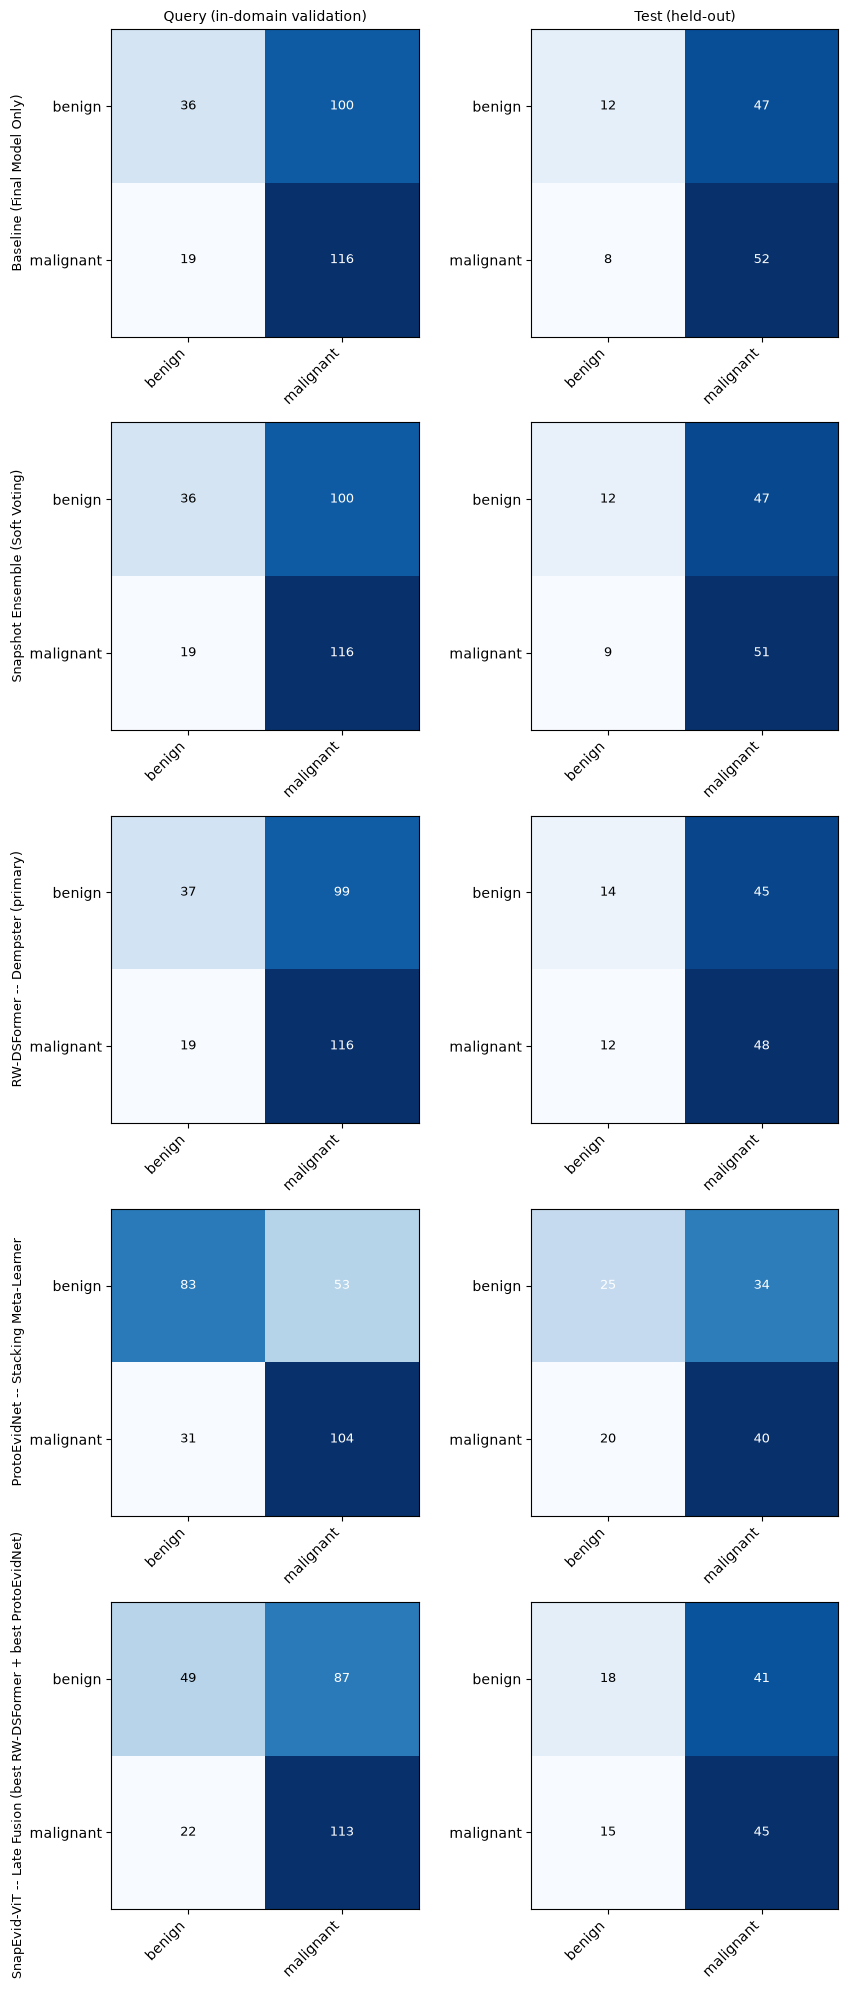

In [40]:
def plot_confusion_matrices(results, methods, splits, class_names, save_path=None):
    n_rows, n_cols = len(methods), len(splits)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4 * n_rows), squeeze=False)

    for r, name in enumerate(methods):
        for col, split in enumerate(splits):
            ax = axes[r][col]
            if split not in results[name]:
                ax.axis("off")
                continue
            cm = results[name][split]["confusion_matrix"]
            ax.imshow(cm, cmap="Blues")
            ax.set_xticks(range(len(class_names)))
            ax.set_xticklabels(class_names, rotation=45, ha="right")
            ax.set_yticks(range(len(class_names)))
            ax.set_yticklabels(class_names)
            if col == 0:
                ax.set_ylabel(name, fontsize=9)
            if r == 0:
                ax.set_title(_SPLIT_LABELS.get(split, split), fontsize=10)
            thresh = cm.max() / 2.0 if cm.max() > 0 else 0.5
            for i in range(cm.shape[0]):
                for j in range(cm.shape[1]):
                    ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                             color="white" if cm[i, j] > thresh else "black", fontsize=9)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Confusion matrix heatmap saved to: {save_path}")
    plt.show()


for exp_name, exp in experiments.items():
    key_methods = [
        "Baseline (Final Model Only)",
        "Snapshot Ensemble (Soft Voting)",
        exp["snapevid_best_ds"],
        exp["snapevid_best_pe"],
        exp["snapevid_name"],
    ]
    plot_confusion_matrices(exp["results"], key_methods, exp["evidence"]["splits"],
                             exp["train_dataset"].classes,
                             save_path=os.path.join(OUTPUT_DIR, f"confusion_matrices_{exp_name}.png"))

## ROC Curves
ROC-AUC was already computed as a scalar per method/split (loophole A6); plotted here as full ROC
curves (`sklearn.metrics.roc_curve` on the positive/malignant-class probability) — one figure per
dataset — for the same curated methods as above, one panel per split, so the full precision/recall
trade-off is visible rather than a single collapsed number, and the two datasets' curves can be
compared side by side.

ROC curves saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/roc_curves_BreakHis.png


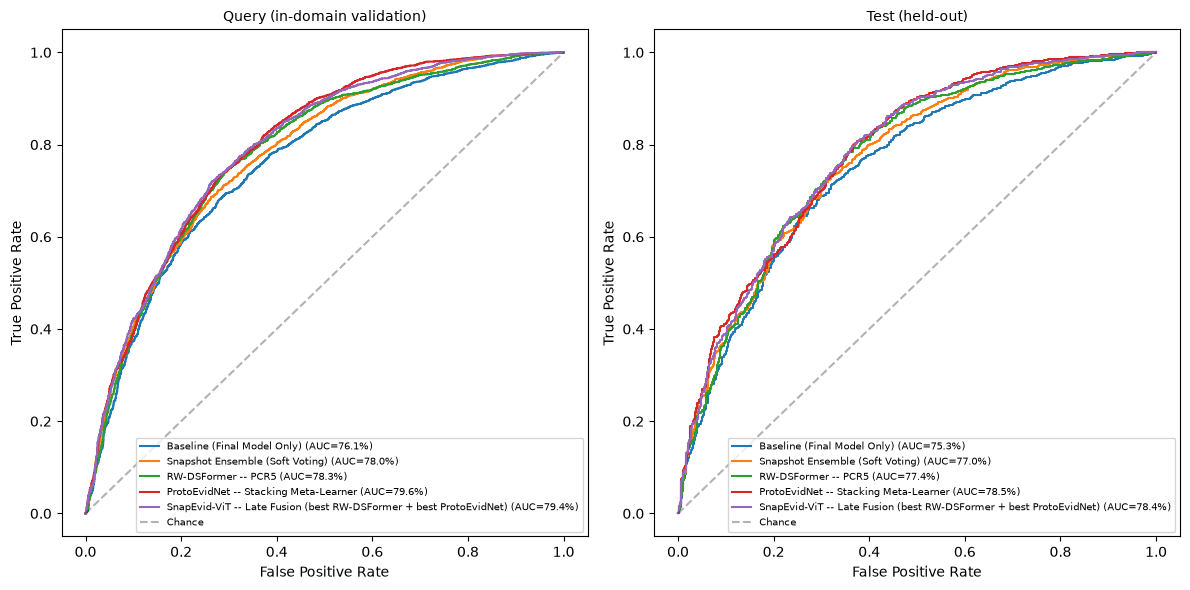

ROC curves saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/roc_curves_BACH.png


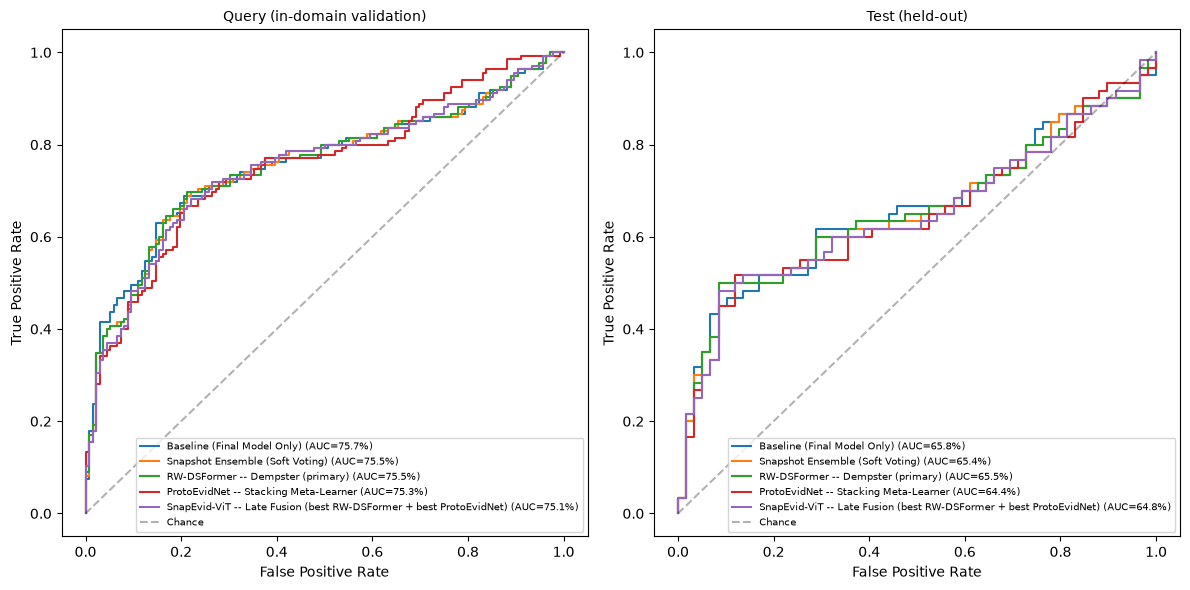

In [41]:
def plot_roc_curves(results, methods, evidence, save_path=None):
    splits = evidence["splits"]
    fig, axes = plt.subplots(1, len(splits), figsize=(6 * len(splits), 6), squeeze=False)

    for col, split in enumerate(splits):
        ax = axes[0][col]
        labels = evidence[f"{split}_labels"]
        for name in methods:
            if split not in results[name]:
                continue
            probs = results[name][split]["probabilities"]
            fpr, tpr, _ = roc_curve(labels, probs[:, 1])
            auc_val = results[name][split].get("auc", float("nan"))
            ax.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.1f}%)")
        ax.plot([0, 1], [0, 1], "k--", alpha=0.3, label="Chance")
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.set_title(_SPLIT_LABELS.get(split, split), fontsize=10)
        ax.legend(fontsize=7, loc="lower right")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"ROC curves saved to: {save_path}")
    plt.show()


for exp_name, exp in experiments.items():
    key_methods = [
        "Baseline (Final Model Only)",
        "Snapshot Ensemble (Soft Voting)",
        exp["snapevid_best_ds"],
        exp["snapevid_best_pe"],
        exp["snapevid_name"],
    ]
    plot_roc_curves(exp["results"], key_methods, exp["evidence"],
                     save_path=os.path.join(OUTPUT_DIR, f"roc_curves_{exp_name}.png"))

## Uncertainty Quantification Analysis
Belief/plausibility intervals are only meaningful for the Dempster-Shafer-family methods (legacy
heuristic + the 5 RW-DSFormer rules), which carry explicit belief functions; the ProtoEvidNet
methods use different uncertainty representations entirely (Bayesian posterior weights, fuzzy
densities, ER's `m_bar_H`/`m_tilde_H`, or none, for the data-driven stacking learner) and aren't
comparable on the same belief/plausibility scale. Reported per dataset.

In [42]:
for exp_name, exp in experiments.items():
    print("=" * 80)
    print(f"DEMPSTER-SHAFER BELIEF / PLAUSIBILITY - {exp_name} (Test split)")
    print("=" * 80)
    for name, res in exp["results"].items():
        t = res.get("test", {})
        if "belief" not in t:
            continue
        interval = t["plausibility"] - t["belief"]
        print(f"{name:45s} | Belief: {t['belief']:.4f} | Plausibility: {t['plausibility']:.4f} "
              f"| Interval: {interval:.4f}")

    print(f"\n[{exp_name}] Reliability (normalized query-split accuracy) per snapshot, used by both "
          "RW-DSFormer (discounting) and ProtoEvidNet (BMA/Choquet/ER weights):")
    _snaps = exp["evidence"]["per_snapshot"]
    if num_snapshots_to_use is not None and num_snapshots_to_use < len(_snaps):
        _snaps = _snaps[-num_snapshots_to_use:]
    _rels = [s["query_accuracy"] for s in _snaps]
    _max_rel = max(_rels) if max(_rels) > 0 else 1.0
    for i, r in enumerate(_rels):
        print(f"  Snapshot {i + 1}: raw query acc = {100 * r:.2f}% -> reliability = {r / _max_rel:.4f}")
    print("=" * 80)

DEMPSTER-SHAFER BELIEF / PLAUSIBILITY - BreakHis (Test split)
DS-Hybrid (Legacy Heuristic, ablation)        | Belief: 0.9377 | Plausibility: 0.9383 | Interval: 0.0006
RW-DSFormer -- Dempster (primary)             | Belief: 0.6936 | Plausibility: 0.9365 | Interval: 0.2429
RW-DSFormer -- Yager                          | Belief: 0.6358 | Plausibility: 0.9390 | Interval: 0.3032
RW-DSFormer -- Dubois-Prade                   | Belief: 0.6358 | Plausibility: 0.9390 | Interval: 0.3032
RW-DSFormer -- Murphy                         | Belief: 0.6808 | Plausibility: 0.9361 | Interval: 0.2553
RW-DSFormer -- PCR5                           | Belief: 0.7048 | Plausibility: 0.9310 | Interval: 0.2262

[BreakHis] Reliability (normalized query-split accuracy) per snapshot, used by both RW-DSFormer (discounting) and ProtoEvidNet (BMA/Choquet/ER weights):
  Snapshot 1: raw query acc = 76.03% -> reliability = 1.0000
  Snapshot 2: raw query acc = 74.54% -> reliability = 0.9805
  Snapshot 3: raw query acc = 73

## Visualization Phase
Builds a dedicated `batch_size=1` loader for visualization (`vis_query_loader`) — `query_loader`
itself uses `batch_size` for faster feature extraction (loophole B7), which would otherwise break
the index alignment this function relies on. Runs once per dataset, each using whichever method had
the best held-out Test accuracy *for that dataset*. Each figure is both **saved to disk**
(`query_visualizations_BreakHis.png` / `query_visualizations_BACH.png`) and **displayed inline**
below its cell, so both datasets' Original/Activation-Map/Grad-CAM/LIME panels are visible directly
in the notebook, not just as files you'd have to open separately.


GENERATING VISUALIZATIONS - BreakHis
Using predictions from best method: ProtoEvidNet -- Stacking Meta-Learner

GENERATING VISUALIZATIONS FOR QUERY IMAGES
Selected 2 correctly predicted samples (one per class)
Visualizing Class 0 (benign), Sample 1
  Generating LIME explanation...


  0%|          | 0/500 [00:00<?, ?it/s]

Visualizing Class 1 (malignant), Sample 1731
  Generating LIME explanation...


  0%|          | 0/500 [00:00<?, ?it/s]


Visualization saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/query_visualizations_BreakHis.png


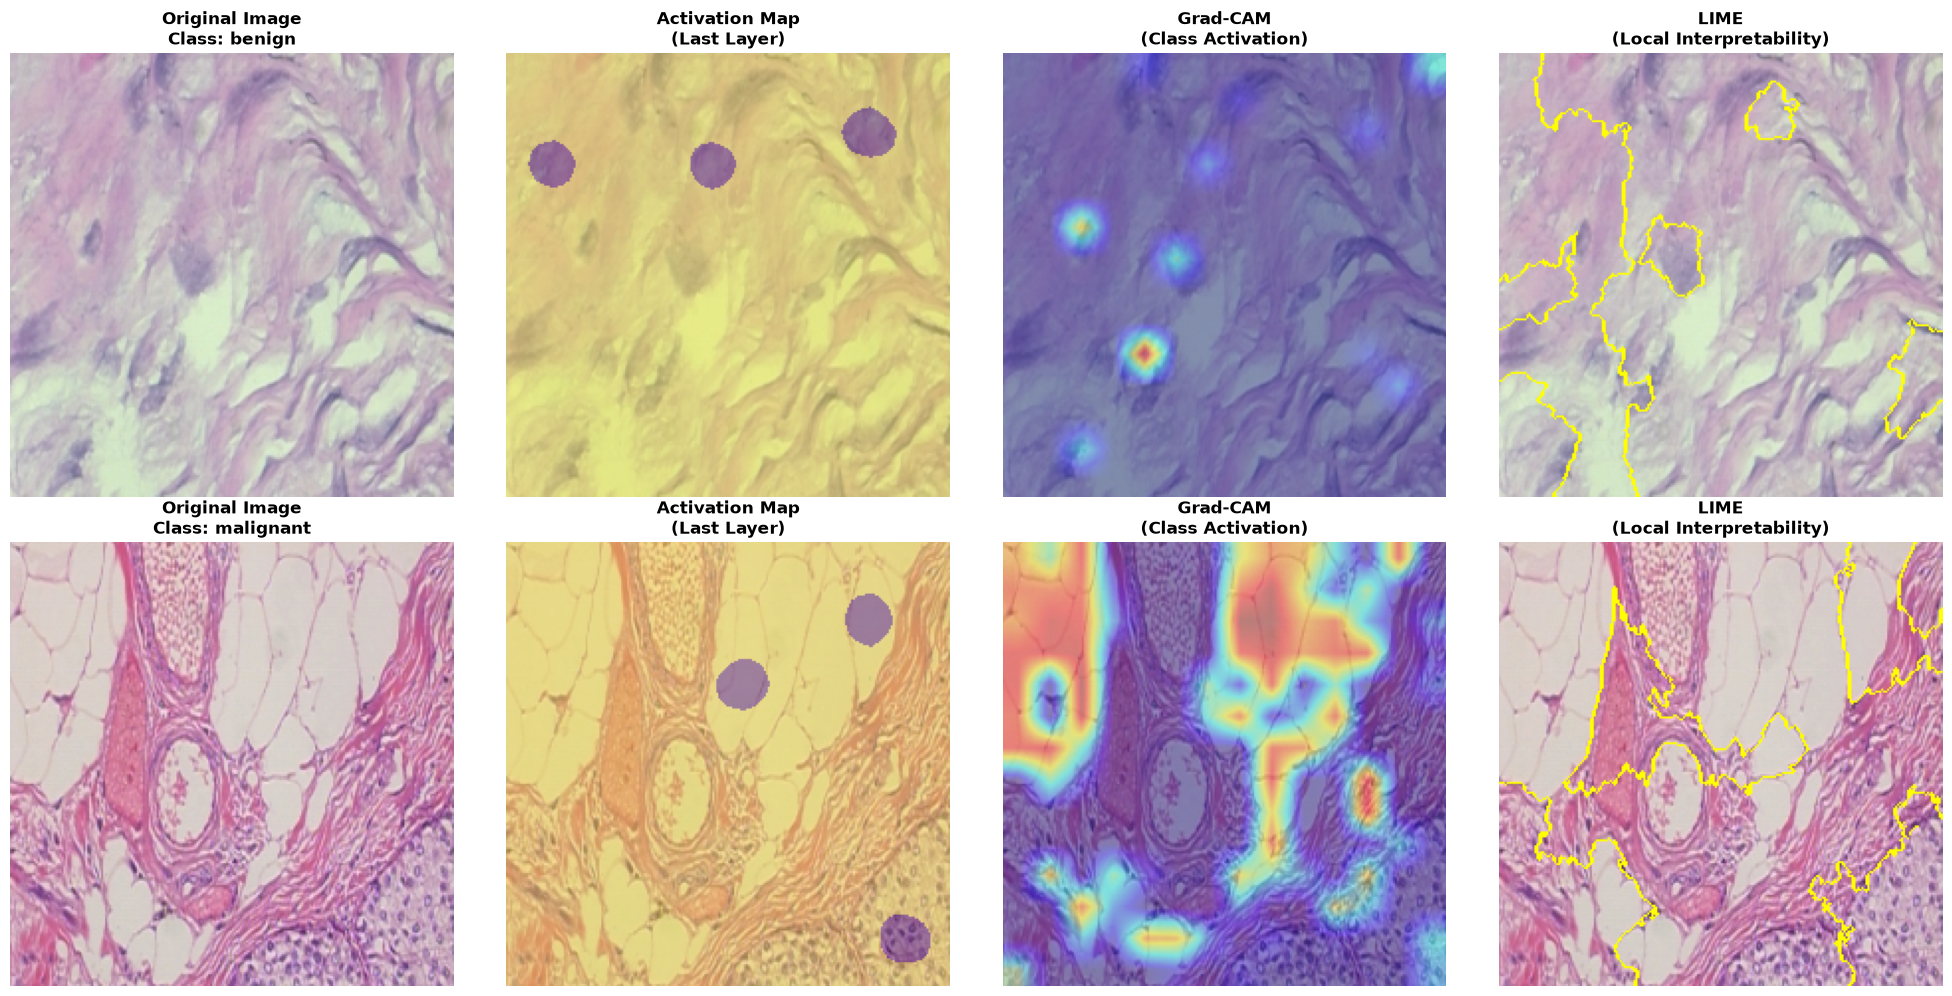


GENERATING VISUALIZATIONS - BACH
Using predictions from best method: ProtoEvidNet -- Stacking Meta-Learner

GENERATING VISUALIZATIONS FOR QUERY IMAGES
Selected 2 correctly predicted samples (one per class)
Visualizing Class 0 (benign), Sample 0
  Generating LIME explanation...


  0%|          | 0/500 [00:00<?, ?it/s]

Visualizing Class 1 (malignant), Sample 136
  Generating LIME explanation...


  0%|          | 0/500 [00:00<?, ?it/s]


Visualization saved to: /home/talha_k/Downloads/MAPA-CLIP-FDB/05 - DST Breast ⛔/output/query_visualizations_BACH.png


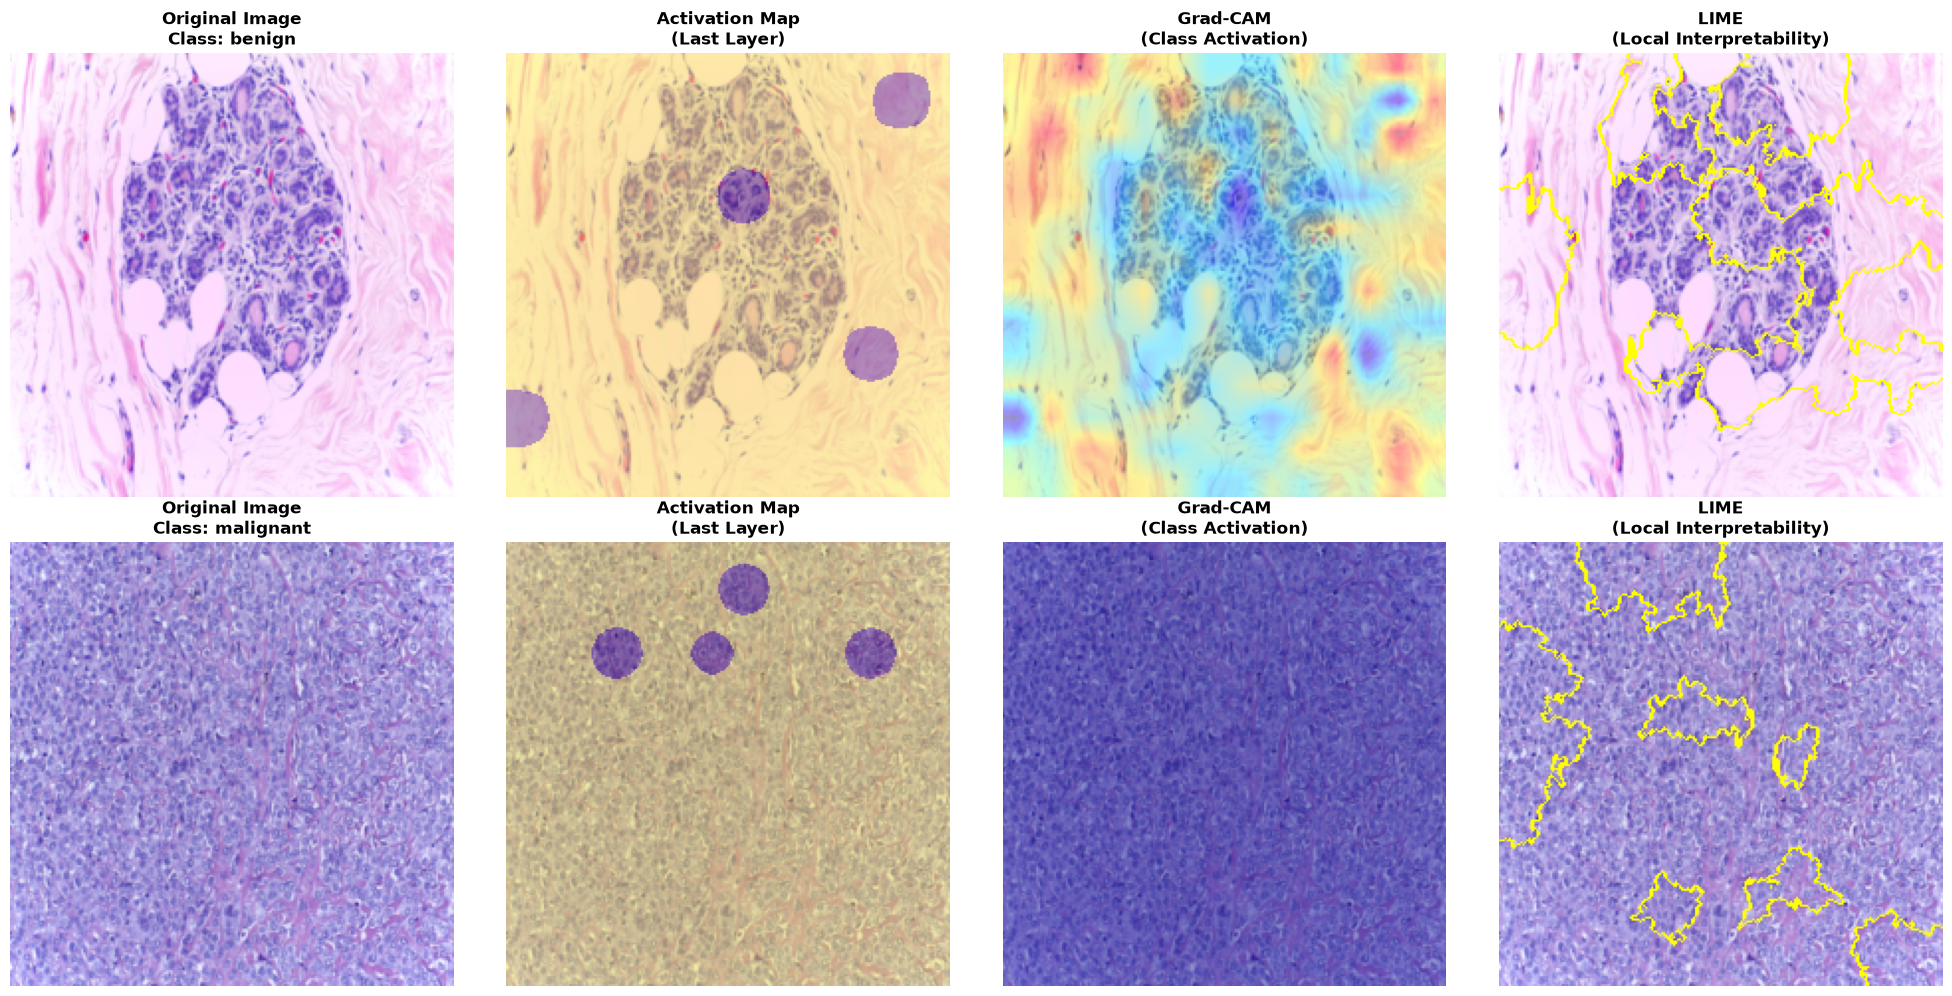

In [43]:
for exp_name, exp in experiments.items():
    print("\n" + "=" * 80)
    print(f"GENERATING VISUALIZATIONS - {exp_name}")
    print("=" * 80)

    results = exp["results"]
    best_name_here = max(results, key=lambda k: results[k]["test"]["accuracy"])
    print(f"Using predictions from best method: {best_name_here}")

    vis_query_loader = DataLoader(exp["query_set"], batch_size=1, shuffle=False)
    best_query_preds = results[best_name_here]["query"]["predictions"]

    visualize_query_predictions(
        exp["model"],
        vis_query_loader,
        exp["support_loader"],
        exp["train_dataset"],
        best_query_preds,
        exp["evidence"]["query_labels"],
        save_path=os.path.join(OUTPUT_DIR, f"query_visualizations_{exp_name}.png")
    )

## Execution Complete

In [44]:
print("\n" + "=" * 80)
print("EXECUTION COMPLETE")
print("=" * 80)


EXECUTION COMPLETE
